# Семинар 3. Свёртка на практике и цикл обучения

## Операция свёртки руками

Источники:
- [1] **LeNet**: [Yann LeCun et al., 1998](http://vision.stanford.edu/cs598_spring07/papers/Lecun98.pdf), примерно 84 тысячи цитирований
- [2] **ResNet**: [Kaiming He et al., 2015](https://arxiv.org/abs/1512.03385), примерно 310 тысяч цитирований

- Исследование и интерпретация свёрточных слоёв: [Matthew D Zeiler, Rob Fergus, 2013](https://arxiv.org/abs/1311.2901), примерно 26 тысяч цитирований

На этом занятии мы обсудим, как извлекать признаки из изображений так, чтобы они были согласованы со свойствами, которые мы ожидаем. Одним из таких свойств, например, является инвариантность относительно сдвигов, то есть при сдвигах класс изображения не изменяется. Мы обсудим как внести нужные нам свойства в архитектуру модели (внести Inductive bias) и как это связано с операцией свёртки. Затроним как гиперпараметры архитектуры, так и  их  связь  с рецептивным полем(receptive field).

---

## Операция свёртки

### Мотивация

В прошлом семестре мы уже обучали модели для классификации изображений (распознавания цифр).

<font color='orange'>**Вопрос:**</font> Давай вспомним, какие приёмы мы использовали для повышения качества?

#### Ответ:

Одним из основных способов было увеличение выборки (аугментации) с помощью поворотов, сдвигов и многих других техник, но мы всегда предполагали, что наши **изменения данных не влияют** на класс.

Например, если немного сдвинуть изображения цифры, то человек все еще сможет распознать, что именно изображено, именно на таких предположениях мы строили аугментации. **Правильная аугментация не должна изменять класс.** Мы уже поняли, что такое "правильная", но для полноты картины нам важно понять, что такое "неправильная" аугментация, или разобрать примеры.

Примеры **"неправильных" аугментаций**:

- Отражение цифр
- Поворот текста
- Изменение контрастности еды


В целом, когда говорят об изображениях, всегда предполагают "правильность" аугментации сдвигами или, иными словами `инвариантность относительно сдвигов`. Это предположение разумно, так как сдвиг пикселей не должен менять класс объекта. Мы бы хотели, чтобы модель училась распознавать объекты независимо от их пространственных координат: яблоко не перестанет быть яблоком, если мы его сдвинем чуть влево перед фотографией.

Раньше мы закладывали наши знания о данных (априорные знания) в аугментации, тем самым добавляли некую регуляризацию и пытались избавиться от переобучения, так как чем больше выборка, тем лучше обобщающая способность модели и меньше переобучение. Такой подход действительно был оправдан, но давай вспомним, как ещё люди старались улучшить качество классификации в машинном обучении?

Стандартные приёмы в обработке изображений:
- Поиск и подсчёт геометрических фигур
- Фильтры (размытие, выделение границ и т.д.)
- Преобразование Фурье
- Морфологические операции
- Сжатие, пирамиды Лапласа
- Многое другое, что имеется в OpenCV

Вся область до появления нейронных сетей подбирала всё более сложные и интересные признаки, которые можно извлечь из изображения для более точной классификации. Что же поменялось? Чего смогли сделать нейронные сети, что не получалось в классическом машинном обучении?

Ранее мы говорили, что нейросети можно рассматривать как последовательное извлечение всё более сложных признаков. Так что выйдет, если мы обучим полносвязанные глубокие нейронные сети для классификации изображений?

Выше мы говорили, что учёт априорных знаний (например, аугментаций) сильно помогает в проблеме переобучения, так как модель извлекает более естественные и осмысленные признаки. Если классическое машинное обучение закладывало знания о данных в извлечении фичей для модели, а нейронные сети идейно сами извлекают признаки, то нам следует придумать блоки или даже целые архитектуры, которые учитывают структуру изображений (априорные знания). Когда мы заранее в алгоритм вносим какие-то знания, то закладываем некое индуктивное смещение (`Inductive bias`) в процесс обучения.

Наша цель &ndash; понять или придумать (если ты ещё не знаешь), как в современных архитектурах нейронных сетей используется `inductive bias` на примере классификации изображений, а может и в других доменах.

Выше мы уже выяснили, что самое универсальное требование к извлекаемым фичам &ndash; `инвариантность относительно сдвига`. Как ты думаешь, какие методы получения фичей из классического машинного обучения обладают этим свойством?

К сожалению, методов **инвариантных** относительно сдвига у нас нет в наличии, так как для **инвариантности** требуется слишком много. Попробуем ослабить это свойство, для этого формально запишем наши требования.

**Определение:**

Пусть есть какое-то действие $g$ на объект $x$, тогда под **инвариантностью** функции $f$ относительно $g$ мы понимаем следующее:

$$
\begin{gather*}
f(g \circ x) = f(x)
\end{gather*}
$$

На практике же мы хотим, чтобы извлекаемые фичи были бы "согласованы" со входом, то есть хотим **эквивариантность (equivariant)**.




**Определение:**

Пусть есть какое-то действие $g$ на объект $x$, тогда под **эквивариантностью** функции $f$ относительно $g$ мы понимаем следующее:

$$
\begin{gather*}
f(g \circ x) = g \circ f(x)
\end{gather*}
$$

Выше мы рассмотрели определения для конкретного действия $g$, например, сдвига на 1 пиксель влево, но чаще всего нас интересует семейство действий. В математике для описания семейств объектов одной природы используется понятие группы, поэтому определение **эквивариантности** можно записать так.




**Определение:**

Пусть есть группа $G$ и определено действие на элементы множества $X$, тогда под **эквивариантностью** функции $f$ относительно $G$ мы понимаем следующее:

$$
\begin{gather*}
f(g \circ x) = g \circ f(x), \quad \forall g \in G, \forall x \in X
\end{gather*}
$$



Если мы рассмотрим множество всех изображений, то сдвиги, повороты, отражения будут образовывать группу. Мы не будем формально проверять свойства групповых операций и оставим это любопытному читателю. Заметим важное для нас утверждение.

**Утверждение:**

Композиция эквивариантных функций является **эквивариантной** функцией.

Для нас это значит, что последовательное применение **эквивариантных** слоев реализует **эквивариантную** функцию, значит мы можем достаточно просто собирать **эквивариантные** нейросети.

<font color='orange'>**Вопрос:**</font> Какие методы получения фичей из классического машинного обучения обладают **эквивариантны относительно сдвига**?

#### Ответ:

Самым **простым методом** эквивариантным относительно сдвига являются фильтры, то есть базовую идею можно озвучить так:

1) Мы хотим обучать модель, чтобы извлекаемые фичи были эквивариантны относительно сдвига.

2) Мы можем заложить эти знания в аугментацию выборки, а можем в архитектуру, алгоритм обучения, то есть добавить `inductive bias`.

3) Мы знаем, что уже есть фильтры, они достаточно выразительны (могут выделять границы, размывать и т.д.).

4) Мы можем использовать в качестве базового блока не линейный слой, который не эквивариантен относительно сдвига, а обучаемый фильтр.

5) Обучая фильтры можно будет извлекать все более сложные эквивариантные относительно сдвига признаки

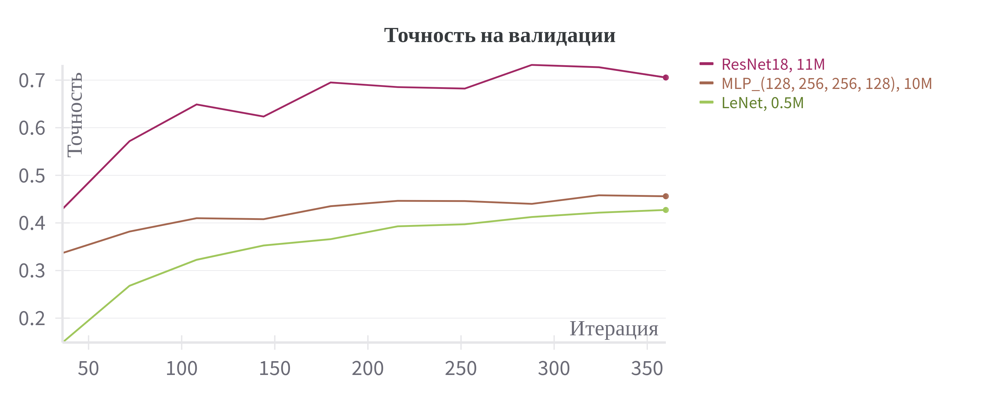

На рисунке выше представлены три модели для классификации датасета `Imagenette`; все параметры обучения кроме архитектуры модели **были зафиксированы**.

- `LeNet`[[1]](http://vision.stanford.edu/cs598_spring07/papers/Lecun98.pdf) &ndash; сверточная архитектура с 0,5 миллиона обучаемых параметров.
- `ResNet18` [[2]](https://arxiv.org/abs/1512.03385) &ndash; сверточная архитектура с 11 миллионами обучаемых параметров.
- `MLP_*` &ndash; полносвязная архитектура с 10 миллионами обучаемых параметров.

По графикам мы видим, что даже маленькая сверточная сеть `LeNet`, при числе параметров в 20 раз меньше, может получить качество, сравнимое с `MLP`. При этом свёрточная архитектура `ResNet18` со схожим числом параметров показывает качество заметно лучше, чем `MLP`. Из этих графиков мы можем сделать вывод, что сверточные архитектуры при меньшем числе параметров работают лучше, чем полносвязные нейросети при решении задачи классификации изображений. Подробнее о получении и воспроизведении результатов можно будет узнать на следующем занятии.

### Сверточный слой

####  Примеры фильтров


Много примеров было рассмотрено на занятии по компьютерному зрению на курсе "Технологическая практика" в осеннем семеcтре, ноутбук доступен по [ссылке](https://github.com/mmp-practicum-team/mmp_practicum_fall_2025/blob/main/Seminars/04-knn_and_cv/Seminar_4_cv_msu.pdf).

Поиграться с различными фильтрами можно по [ссылке](https://setosa.io/ev/image-kernels/).

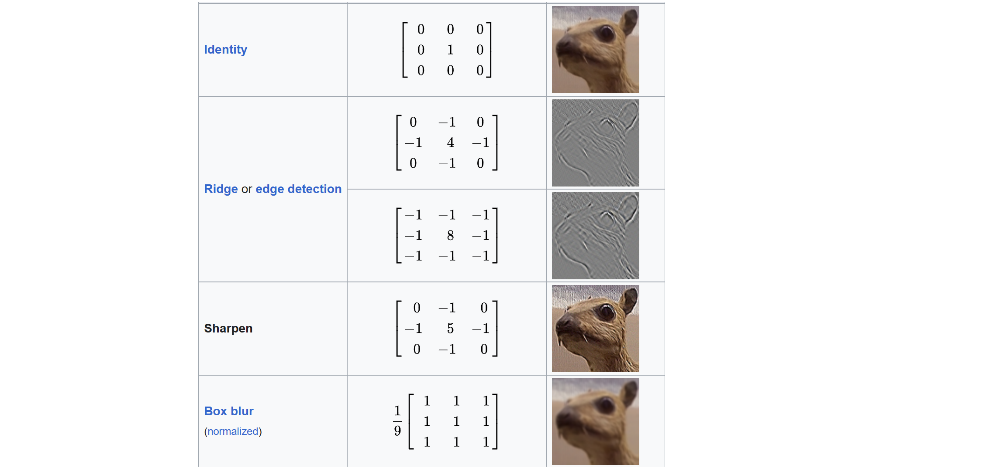

[Источник](https://en.wikipedia.org/wiki/Kernel_(image_processing)

#### Фильтры в PyTorch

В нейронных сетях **обучаемые фильтры принято называть свёртками**. Сначала постараемся понять самое простое: как происходит `forward pass`.

**Свёртка 2D изображения** &ndash; агрегация данных об интенсивности пикселей на изображении в соответствии с определенным набором правил.



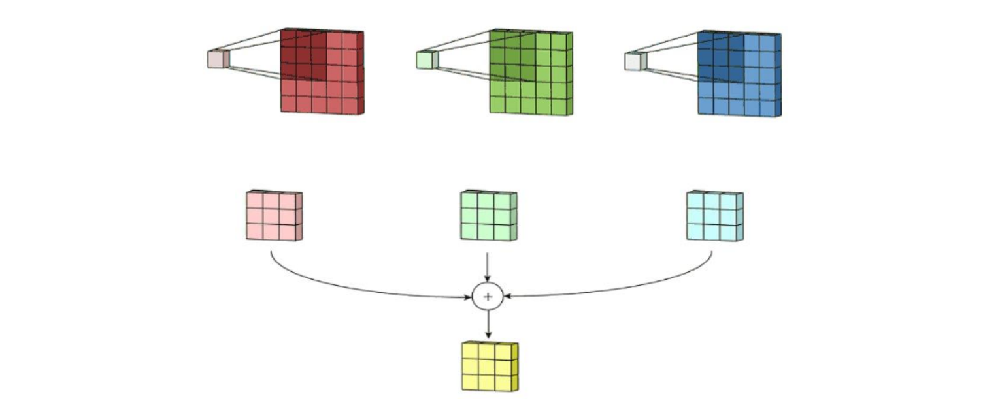

**Пример:** Операция свёртки многоканального изображения $U$ с ядром $K$:

$
\begin{align*}
&V(x,y,t) = \sum\limits_{i=x-\delta}^{x-\delta} \sum\limits_{j=y-\delta}^{y-\delta}\sum\limits_{s=1}^{S} K(i-x+\delta,j-y+\delta,s,t)U(i,j,s),\\
&U \in \mathbb{R}^{W \times H \times S}, \quad V \in \mathbb{R}^{W' \times H' \times T}, \quad K \in \mathbb{R}^{k \times k \times S \times T}, \quad k = 2 \delta + 1.
\end{align*}
$

Заметим, что свёртка $K$ это **не матрица**, а **тензор**!

Посмотрим на это выражение подробнее, и постараемся понять какие размерности у $K$, $U$ и результата $V$.

- $U$ обозначает наше изображение c $S$ каналами, индиксируясь по $(i, j)$ и фиксированном $s$ мы проходим по всем пикселям отдельного канала. При фиксированных $(i, j)$ и итерируясь по $s$ мы смотрим на изменение пикселя по каналам

- $V$ это получаемое изображение с $T$ каналами.

- $K$ ядро, которая преобразует изображение с $S$ каналами в изображение c $T$ каналами и ядром размера $k$.


<font color='orange'>**Вопрос:**</font> Как будет выглядеть свёртка, которая преобразует RGB изображение в ЧБ?

<font color='orange'>**Вопрос:**</font> Как будет выглядеть свёртка, которая добавляет новый канал, равный сумме красного и зеленого?

<font color='orange'>**Вопрос:**</font> Сколько обучаемых параметров у свёртки $K$?

#### Ответ:

1. Для перевода изображения в ЧБ нужно сложить R с весом  0.299, G с весом 0.587 и B с весом 0.114. Значит нам нужна свёртка с ядром размера 1 и весами 0.299, 0.587, 0.114 на всех каналах. Возможен и более простой вариант с весами равными $\frac{1}{3}$. Свёртка будет иметь 3 канала на входе ($S=3$) и 1 каналом на выходе ($T=1$).

2. Это будет свёртка с ядром размера 1. Веса на канале R будут (1, 0, 0), для канала G &ndash; (0, 1, 0), для канала B (0, 0, 1), для нового канала веса будут (1, 1, 0). Получается $S=3$, $T=4$.

3. Параметров у свёртки $K$ будет $STk^2$ параметров.

#### Гиперпараметры сверточного слоя

Сначала нам стоит ответить на **вопрос:** Что мы хотим от сверток? Какие именно признаки мы хотим извлекать? Так как именно от ответа будут зависеть параметры, которые мы опишем ниже.


Все параметры можно разделить на 2 группы.
- Параметры размерности свёртки
- Параметры применения свёртки

**Параметры размерности свёртки**



- **kernel_size:** Отвечает за размер ядра, например при **kernel_size=3** мы будем рассматривать свёртки с ядром порядка 3, то есть будем агрегировать 9 пикселей с канала.

- **in_channels:** Соответствует числу каналов изображения $U$.

- **out_channels:** Соответствует числу каналов результата $K$.

<font color='orange'>**Вопрос:**</font> Каким должен быть размер ядра, если мы хотим учитывать **локальные** свойства изображения?

<font color='orange'>**Вопрос:**</font> Каким должен быть размер ядра, если мы хотим учитывать **глобальные** свойства изображения?

#### Ответ:

Для локальных свойств лучше использовать свёртки с маленьким размерам ядра, для глобальных наоборот.

На практике оказывается, что каждый канал является хорошей фичей (признаком), аналогично элементам в скрытом состоянии MLP. Так как мы хотим использовать больше признаков, то часто свёртки берут достаточно широкими (128, 256 каналов), то есть на практике **in_channels** и **out_channels** берут по аналогии с **in_features** и **out_features**.

Такая интуиция работает, так как мы можем рассматривать свёртку как линейные слои для окрестности пикселя, то есть с каждым слоя мы все больше уточняем признаки (**feature map**).

**Параметры применения свёртки**

- **Stride:** Определяет шаг, с которым ядро свёртки проходит по матрице

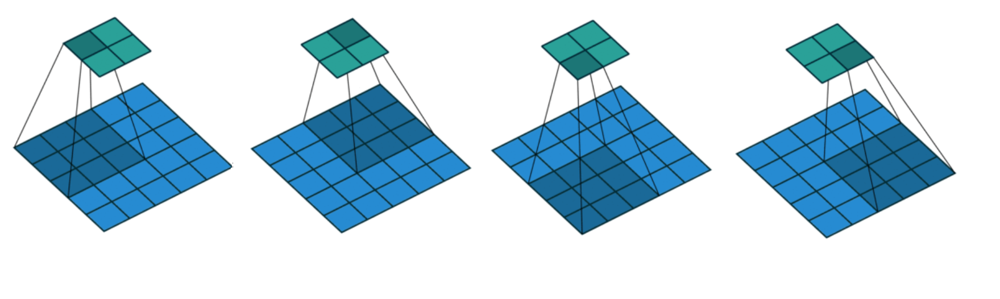

- **Dilation:**

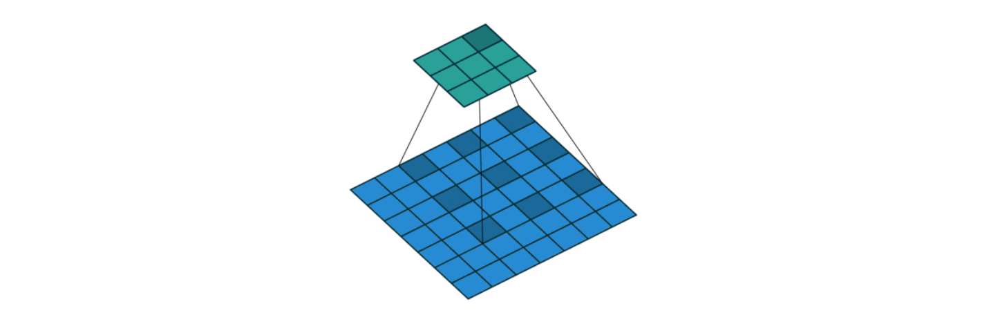

- **Padding:** Определяет то чем и насколько пикселей мы будем расширять изображение. Обычно можно выбрать такое количество пикселей, чтобы размеры входа и выхода совпадали.


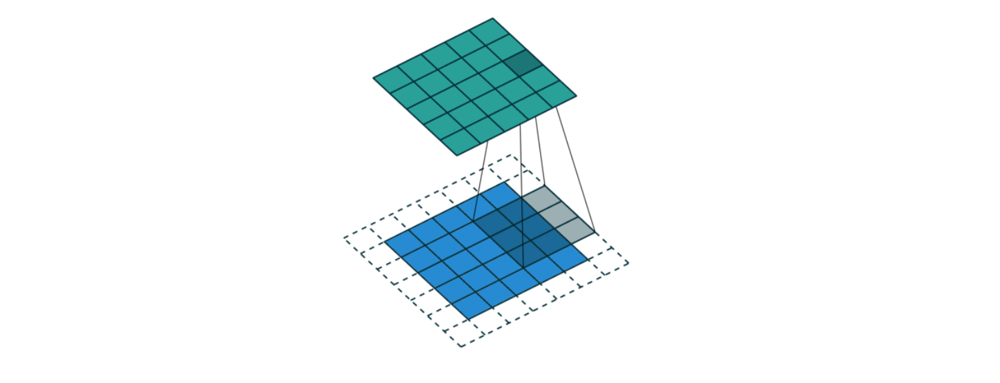

[Источник визуализаций](https://github.com/vdumoulin/conv_arithmetic/blob/af6f818b0bb396c26da79899554682a8a499101d/README.md)

Одной из главных проблем на практике является определение размеров изображения после применения свёртки. Существует общая формула:
$$ H_{out} = \lfloor \frac{H_{in} - 2 \cdot \mathrm{Padding} - \mathrm{Dilation} \cdot (k - 1) - 1}{\mathrm{Stride}}\rfloor - 1$$

Однако, на практике иногда удобнее проверить размеры явно, например, вывести.


### Рецептивное поле (Receptive field)

Мы уже обсуждали, что для глобальных и локальных свойств лучше взять свёртки с разными ядрами. На самом деле при этих рассуждениях мы неявно опираемся на следующее определение:

**Receptive field** &ndash; размер части изображения, которая влияет на значение нейрона спустя несколько слоев. Иными словами, зона покрытия изображения нейроном.

**Примеры:**

1) При использовании полносвязного слоя **receptive field** совпадает с размером изображение

2) При применении одной свёртки с ядром 3 **receptive field** равен $3\times3$.

2) При применении двух последовательных сверток с ядром 3 **receptive field** равен $5\times5$.

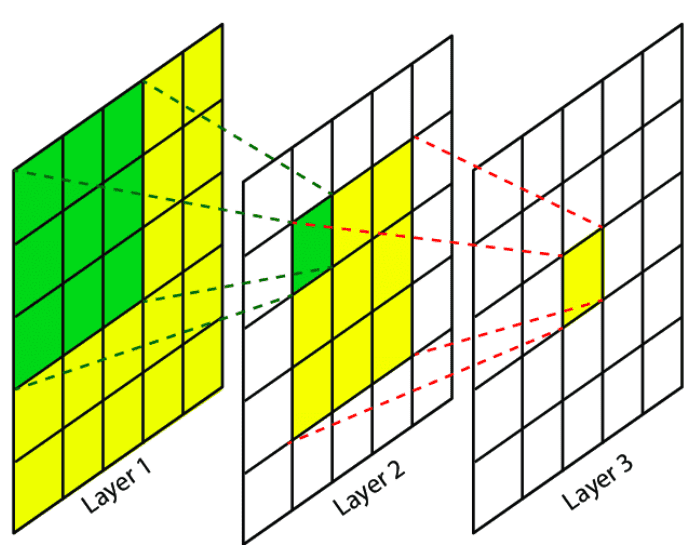

[Источник](https://theaisummer.com/receptive-field/)

Получаем следующее **правило**:

1) Чем больше сверточных слоев или чем больше **stride**/**dilation** у сверток, тем больше **receptive field**.

2) Чем больше **receptive field** у нейрона, тем больше **глобальных признаков** (свойств изображения) он знает.

<font color='orange'>**Вопрос:**</font> Какой receptive field у двух подряд идущих свёрток с ядром 3? Сколько в них параметров (можно считать, что 1 канал на входе и 1 на выходе)?

#### Ответ:

Receptive field будет размером 5, параметров будет 18. Если бы мы сразу использовали бы свертку с размером 5, то получили бы тот же receptive field, но при 25 параметрах.

### Pooling Layers

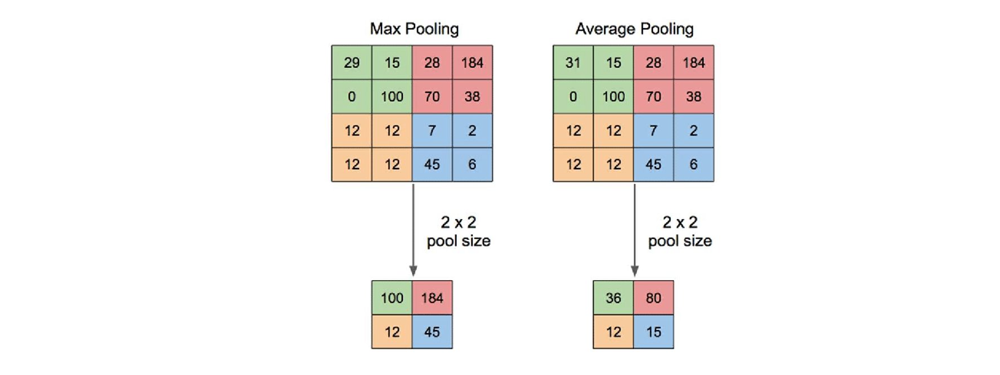

[Источник](https://www.researchgate.net/figure/llustration-of-Max-Pooling-and-Average-Pooling-Figure-2-above-shows-an-example-of-max_fig2_333593451)

**Pooling** слои позволяют увеличить зону покрытия, при этом не добавляя обучающих параметров. Кроме того, слои пулинга не приводят к затуханию градиентов, то есть мы можем сделать более глубокую нейросеть. Такая техника являет  **legacy** более старых архитектур, современные подходы используют параметр **stride** для достижения похожего эффекта.

<font color='orange'>**Вопрос:**</font> Какие веса и параметр **stride** должен быть у сверточного слоя, чтобы он работал эквивалентно **average pooling**?

#### Ответ:

Stride и размер ядра должны быть равными как и число каналов на входе и на выходе. Все веса свёртки должны быть одинаковыми и быть равными $\frac{1}{k^2}$, где $k$ размер ядра.

### Реализации сверток

Внутри свёртки реализованы сильно хитрее с многими оптимизациями, но какой именно алгоритм и библиотека используется в реализации, зависит от каждого отдельного случая.

Возможные реализации свёртки:

1) Матричных умножения: через сведение к [GEMM](https://spatial-lang.org/gemm) и использованию оптимизированных библиотек линейной алгебры

2) [Winograd](https://discuss.pytorch.org/t/why-does-winograd-algorithm-speedup-convolution-given-that-mul-and-add-cost-the-same-clock-cycles-on-gpu/89993/4): алгоритм для сверток размером $3 \times 3$

3) FFT (Fast Fourier Transform): для сверток больших размеров

Для использования наиболее подходящего алгоритма под твою задачу и систему стоит использовать ([подробнее тут](https://discuss.pytorch.org/t/what-does-torch-backends-cudnn-benchmark-do/5936)):

```python
torch.backends.cudnn.benchmark = True
```

Обратим внимание, что свёртки часто реализуются через матричные умножения, через которые можно очень просто и эффективно делать `backward`.

Мы не будем подробно разбирать реализации и эффективные подходы, так как это достаточно трудная и отдельная задача. Что для нас важно, что мы пользуемся некой абстракцией, которая может быть реализована через совершенно разные алгоритмы под капотом. За этим следуют некие **проблемы воспроизводимости**, что будет для нас крайне важно, об этом подробнее поговорим на семинаре.

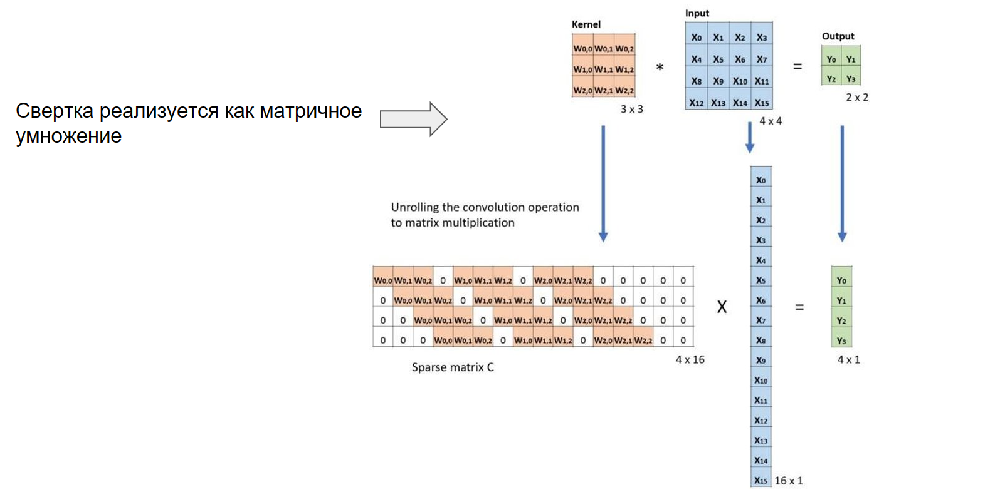

### Общая идея сверточных сетей


Выше мы описали базовые слои (свёрточный, pooling) из которых будем собирать нейронную сеть. Мы можем, например, собрать свёрточный блок, добавить нелинейности и потом pooling. После некого количества таких слоев мы получим карту признаков (`feature map`), дальше можно сделать стандартный однослойный классификатор. При таком подходе мы благодаря свёрточным сетям извлечем хорошие признаки и будем обучать на них логистическую регрессию.

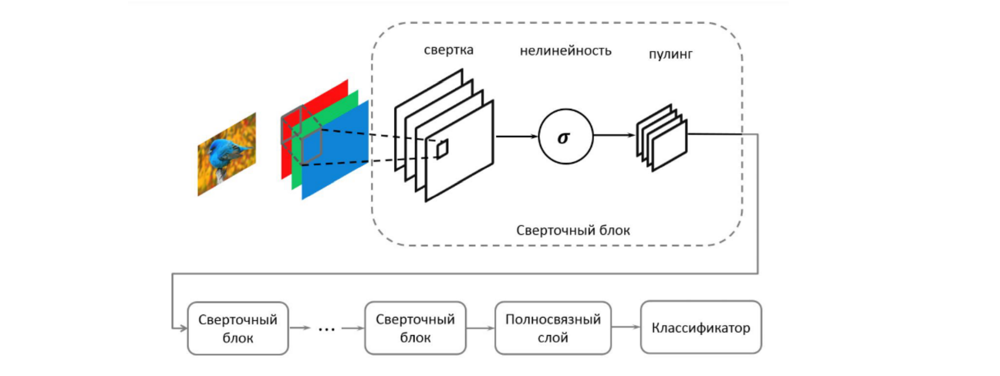

[Источник](http://www.machinelearning.ru/wiki/images/7/71/Voron-ML-DeepLearning-slides.pdf)

<font color='orange'>**Вопрос:**</font> Почему между свёрточными слоями мы не используем полносвязные блоки? Благодаря этому мы могли бы повысить **receptive field**?

#### Ответ:

Так мы потеряем эквивариантность, то свойство, ради которого мы и начали использовать свёрточные блоки.

О том какие существуют свёрточные нейронные архитектуры и какие идеи за ними стоят мы обсудим на следующем занятии.

## Первые попытки заглянуть внутрь


### Что исследовалось, когда появились сверточные нейросети?

[Matthew D Zeiler, Rob Fergus, 2013](https://arxiv.org/abs/1311.2901), примерно 26 тысяч цитирований

#### Чувствительность к маскированию (окклюзия изображений)

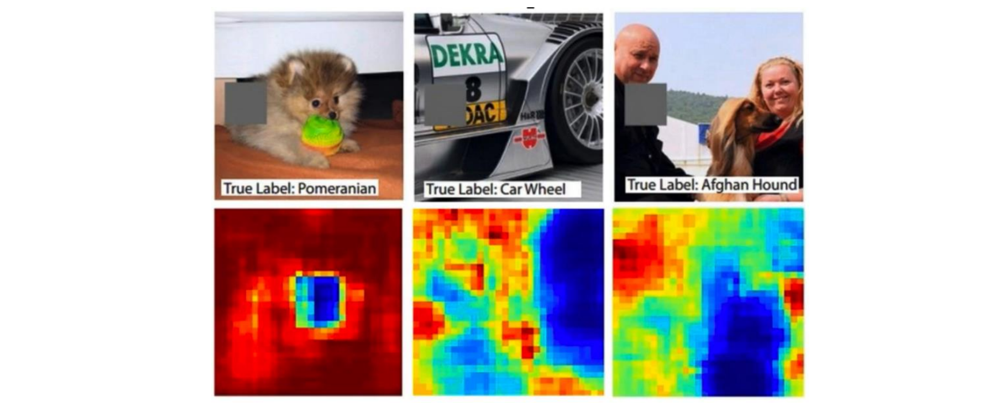

### Чувствительность фильтров

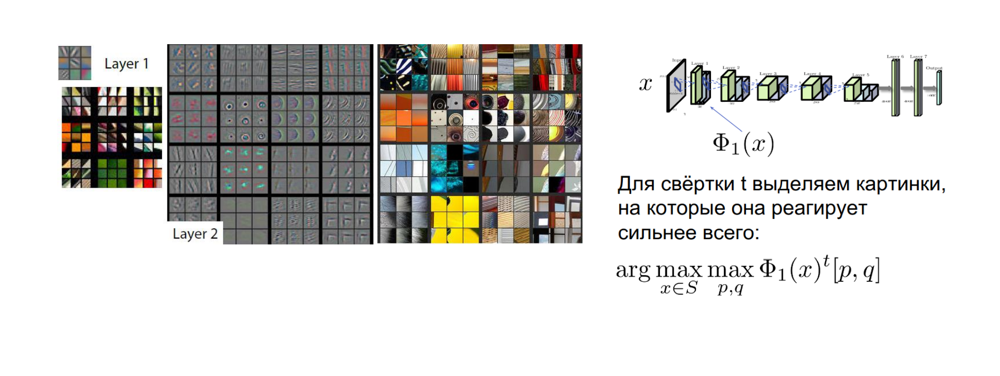

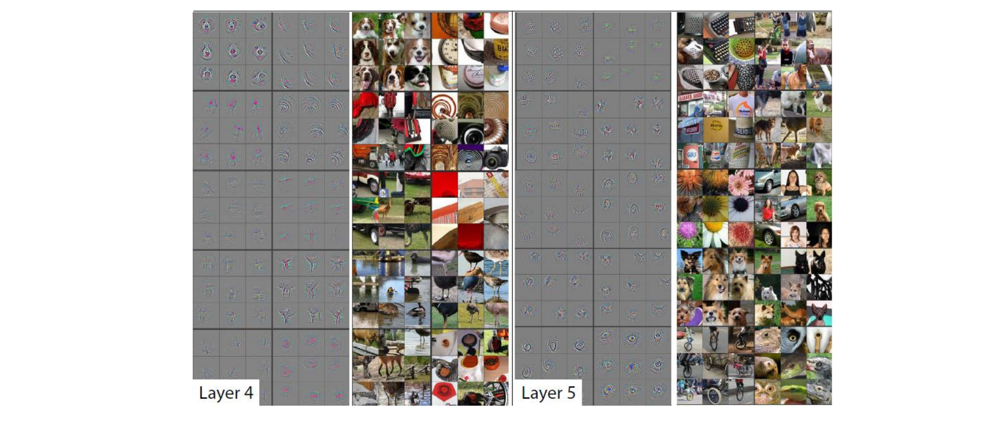

### Заключение

- Операция свёртки эквивариатна относительно сдвигов, то есть закладывает `inductive bias` в нашу модель
- В случае сверточного слоя аналогом размерности скрытых состояний является число каналов `feature map`
- При работе со свёртками мы извлекаем признаки локально и глобально в зависимости от **receptive field**
- Мы можем добавить pooling слои для увеличения **receptive field** или брать свёртки с большим **stride**
- В PyTorch есть разные реализации в зависимости от системы, что влияет на воспроизводимость

## Цикл обучения: CNN, аугментации, transfer learning


Источники:

- [Сборка нейронной сети PyTorch](https://pytorch.org/tutorials/beginner/blitz/neural_networks_tutorial.html#sphx-glr-beginner-blitz-neural-networks-tutorial-py)

- [Обучение классификатора для CIFAR-10](https://pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html#sphx-glr-beginner-blitz-cifar10-tutorial-py)

- [Reproducibilty PyTorch](https://pytorch.org/docs/stable/notes/randomness.html)

- [Подробное описание получения state-of-the-art (SOTA) результатов.](https://pytorch.org/blog/how-to-train-state-of-the-art-models-using-torchvision-latest-primitives/)

- Ноутбук во многом опирается на [этот конспект](https://github.com/mmp-practicum-team/mmp_dl_spring_2025/blob/main/Seminars/08-training/08-training.ipynb)

Здесь ты познакомишься с тем, как писать цикл обучения нейронных сетей с помощью библиотеки PyTorch. В процессе обучения ты будешь наблюдать изменение метрик, значений функций потерь и других показателей, для отслеживания которых их нужно правильно логировать. В ноутбуке ты обучишь свёрточную нейронную сеть (CNN) для классификации датасета **[Imagenette](https://github.com/fastai/imagenette.git)** и сравнишь с transfer learning.  

---

## Цикл обучения

Цикл обучения содержит в себе все необходимые взаимодействия между данными, нейронной сетью и оптимизатором для обучения. Кроме того, он должен быть написан достаточно высокоуровнево, чтобы незначительные изменения каждого компонента не влияли на код обучения.

Идейно цикл обучения выглядит следующим образом:
1. Получение батча данных из датасета;
2. Вычисление нейронной сети на батче данных;
3. Вычисление функции ошибок;
4. Рассчёт градиентов с помощью обратного распространения (backpropagation);
5. Шаг оптимизации;
6. Переход на пункт 1.

[По ссылке](https://wandb.ai/3145tttt/cnn_mmp_2025/overview) можно посмотреть логи `wandb` для всех экспериментов. В ноутбуке в качестве логера используется `comet_ml`. Логи для него доступны [по ссылке](https://www.comet.com/enteralt/cnn-mmp-2025/view/new/panels).

<font color='OrangeRed'>**Важно:**</font> желательно использовать GPU, в ином случае модель будет учиться долго.

Для начала нам необходимо загрузить библиотеки. Также, мы установим режим вывода графиков в векторные форматы.

In [89]:
import os
import random

import numpy as np
import pandas as pd
from PIL import Image
from sklearn.preprocessing import OrdinalEncoder
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

import matplotlib.pyplot as plt
import matplotlib_inline

%matplotlib inline
matplotlib_inline.backend_inline.set_matplotlib_formats('pdf', 'svg')

### Работа с данными

#### Загрузка данных

Самым известным датасетом для классификации изображений является [ImageNet](https://www.image-net.org/). В нем содержится 1000 классов и более 14 миллионов изображений. Обучение моделей классификации даже с помощью современных видеокарт на нём является трудной задачей.

Мы рассмотрим датасет Imagenette, который является подмножеством из 10 самых легко классифицируемых классов датасета Imagenet. Кроме того, Imagenette удобно реализован в `torchvision.datasets.Imagenette`, что делает его удобным датасетом для сравнения разных методов. Мы не будем пользоваться torchvision, так как мы ставим перед собой цель научиться обучать модели от начала до конца. Мы скачаем Imagenette c официального [GitHub](https://github.com/fastai/imagenette#imagenette-1).

[PyTorch страница Imagenette](https://pytorch.org/vision/stable/generated/torchvision.datasets.Imagenette.html#torchvision.datasets.Imagenette).

In [2]:
DATA_DIR = "./imagenette2-160/"

if not os.path.exists(DATA_DIR):
    !wget https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-160.tgz
    !tar -xf ./imagenette2-160.tgz

os.listdir(DATA_DIR)

['.DS_Store', 'train', 'noisy_imagenette.csv', 'val']

#### Обработка данных

Внимательно посмотрим на данные, для этого прочитаем их в pd.DataFrame.

In [3]:
data_df_path = os.path.join(DATA_DIR, 'noisy_imagenette.csv')

data_df = pd.read_csv(data_df_path)
data_df.head()

,path,noisy_labels_0,noisy_labels_1,noisy_labels_5,noisy_labels_25,noisy_labels_50,is_valid
0,train/n02979186/n02979186_9036.JPEG,n02979186,n02979186,n02979186,n02979186,n02979186,False
1,train/n02979186/n02979186_11957.JPEG,n02979186,n02979186,n02979186,n02979186,n03000684,False
2,train/n02979186/n02979186_9715.JPEG,n02979186,n02979186,n02979186,n03417042,n03000684,False
3,train/n02979186/n02979186_21736.JPEG,n02979186,n02979186,n02979186,n02979186,n03417042,False
4,train/n02979186/ILSVRC2012_val_00046953.JPEG,n02979186,n02979186,n02979186,n02979186,n03394916,False


<font color='Orange'>**Вопрос:**</font> Почему для одного объекта есть несколько noisy_labels_*?

In [4]:
tain_val_count = np.unique(data_df.is_valid, return_counts=True)[1].tolist()

print(f"В обучающей выборке {tain_val_count[0]} объектов")
print(f"В валидационной выборке {tain_val_count[1]} объектов")

В обучающей выборке 9469 объектов
В валидационной выборке 3925 объектов


Путь до изображения лежит в `data_df['path']`, метка класса хранится в `data_df_path['noisy_labels_0']`. Нам будет удобнее работать с числовым представлением класса, поэтому переведем каждую метку класса в число с помощью OrdinalEncoder.

In [5]:
enc = OrdinalEncoder()
labels = data_df['noisy_labels_0'].values
labels_enc = enc.fit_transform(labels[:, None]).astype('int').ravel()

names, counts = np.unique(labels_enc, return_counts=True)
print("Информация о таргетах")
print("Присутсвтуют классы:", names.tolist())
print("Количество объектов каждого класса:", counts.tolist())

data_df['target'] = labels_enc
data_df.head()

Информация о таргетах
Присутсвтуют классы: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Количество объектов каждого класса: [1350, 1350, 1350, 1244, 1350, 1350, 1350, 1350, 1350, 1350]


,path,noisy_labels_0,noisy_labels_1,noisy_labels_5,noisy_labels_25,noisy_labels_50,is_valid,target
0,train/n02979186/n02979186_9036.JPEG,n02979186,n02979186,n02979186,n02979186,n02979186,False,2
1,train/n02979186/n02979186_11957.JPEG,n02979186,n02979186,n02979186,n02979186,n03000684,False,2
2,train/n02979186/n02979186_9715.JPEG,n02979186,n02979186,n02979186,n03417042,n03000684,False,2
3,train/n02979186/n02979186_21736.JPEG,n02979186,n02979186,n02979186,n02979186,n03417042,False,2
4,train/n02979186/ILSVRC2012_val_00046953.JPEG,n02979186,n02979186,n02979186,n02979186,n03394916,False,2


#### Работа с данными в PyTorch

Идейно цикл обучения выглядит следующим образом:
1. Получение батча данных из датасета;
2. Вычисление нейронной сети на батче данных;
3. Вычисление функции ошибок;
4. Рассчёт градиентов с помощью обратного распространения (backpropagation);
5. Шаг оптимизации;
6. Переход на пункт 1.

Многие из конструкций выше уже реализованы в PyTorch. Нам не нужно писать их самостоятельно, так как внутри они реализуют весь нужный функционал наиболее эффективно.

Для работы с датасетом нам следует обернуть данные в `torch.utils.data.Dataset`, так как это удобная обертка для данных, которая унифицирует к ним доступ. Использование `torch.utils.data.Dataset` позволяет удобно и эффективно итерироваться и получать доступ к данным. Класс наследник `torch.utils.data.Dataset` должен переопределять магические методы `__len__` и `__getitem__`.


**Важно:** одна из проблем нейронных сетей заключается в переобучении. Для борьбы с ним обычно используют аугментации и трансформации данных. Обычно все аугментации и трансформации применяются к изображениям при обращении к элементам датасета. Такой подход позволяет не хранить аугментированную выборку, что очень важно в случае непрервных изменений (поворот, изменения контраста, яркости и тому подобное). Нейронная сеть, оптимизатор и другие абстракции внутри цикла обучения (кроме датасета) не должны быть зависимы от аугментаций данных.

In [6]:
from torch.utils.data import Dataset, DataLoader

In [7]:
class ImageDataset(Dataset):

    def __init__(self, data_df, is_train, transform):
        super().__init__()
        mask = data_df['is_valid'] != is_train

        self.img_paths = data_df[mask].path.values
        self.targets   = data_df[mask].target.values

        self.transform = transform

    def __getitem__(self, idx):
        path = self.img_paths[idx]
        img_path = os.path.join(DATA_DIR, path)

        # YOUR CODE HERE
        img = Image.open(img_path).convert('RGB')
        img = self.transform(img)

        target = self.targets[idx]

        return img, target

    def __len__(self):
        return len(self.targets)

Для получения батча мы воспользуемся `torch.utils.data.Dataloader`, который позволяет быстро получить батч данных. Реализация Dataloader &ndash; достаточно не тривиальный функционал. Подробно обо всех параметрах можно почитать в документации, но мы обсудим основные.

```python
DataLoader(
    dataset: torch.utils.data.dataset.Dataset[+T_co],
    batch_size: Optional[int] = 1,
    shuffle: Optional[bool] = None,
    sampler: Union[torch.utils.data.sampler.Sampler, Iterable, NoneType] = None,
    batch_sampler: Union[torch.utils.data.sampler.Sampler[List], Iterable[List], NoneType] = None,
    num_workers: int = 0,
    collate_fn: Optional[Callable[[List[~T]], Any]] = None,
    pin_memory: bool = False,
    drop_last: bool = False,
    timeout: float = 0,
    worker_init_fn: Optional[Callable[[int], NoneType]] = None,
    multiprocessing_context=None,
    generator=None,
    *,
    prefetch_factor: Optional[int] = None,
    persistent_workers: bool = False,
    pin_memory_device: str = '',
)
```

- `dataset` &ndash; объект класса `torch.utils.data.Dataset`

- `batch_size` &ndash; размер батча

- `shuffle` &ndash; надо ли перемещивать выборку после каждой эпохи

- `sampler` &ndash; чаще всего ты будешь его оставлять равным `None`, но через этот параметр можно определить более сложное поведение выбора объектов в батче

- `num_workers` &ndash; часто получение объекта &ndash; сложная задача (например, обращение к диску для считывания изображения), поэтому бывает удобно делать это в несколько потоков. Параметр отвечает за количество созданных потоков. **Google Colab** не поддерживает `num_workers > 0`


- `collate_fn` &ndash; функция, с помощью которой собирается батч, чаще всего `None`. Подробнее ты узнаешь в домашних заданиях и на следующих занятиях.

- `drop_last` &ndash; если у нас выборка из 10 изображений, а батч равен 9, то мы не хотим на второй итерации считать градиенты по одному элементу. При `drop_last` последний батч меньшего размера будет пропускаться.


Остальные параметры мы либо разберем ниже, либо на других парах, либо оставим для любознательного читателя.

<font color='Orange'>**Вопрос:**</font> Как отличаются параметры Dataloader при обучении и валидации?

Рассмотрим пример работы с Dataloader с батчом 9. В качестве датасета мы возьмем тензор размера 10. После каждой эпохи мы будем перемешивать данные и не учитывать последний батч, если он меньше остальных.

In [8]:
D = DataLoader(
    torch.arange(10),
    batch_size=9,
    shuffle=True,
    drop_last=True
)

for epoch in range(5):
    for batch in D:
        print(epoch, batch)


0 tensor([0, 2, 1, 5, 3, 7, 8, 4, 6])
1 tensor([3, 0, 4, 7, 6, 5, 1, 9, 2])
2 tensor([2, 6, 3, 8, 5, 0, 7, 1, 4])
3 tensor([7, 6, 0, 2, 4, 5, 3, 1, 9])
4 tensor([4, 5, 3, 7, 6, 1, 9, 2, 8])


#### Аугментация и преобразования

В библиотеке `torchvision` есть отдельный модуль, в котором содержатся различные аугментации. Рассмотреть все аугментации мы не сможем, но достаточно подробный разбор можно найти [на официальном сайте](https://pytorch.org/vision/main/auto_examples/transforms/plot_transforms_illustrations.html#sphx-glr-auto-examples-transforms-plot-transforms-illustrations-py).

Все классические аугментации хранятся в модулях `torchvision.transforms` (подходит для задачи классификации) и `torchvision.transforms.v2`, который содержит больше аугментаций для сегментации и детекции объектов.


[Полный список аугментаций](https://pytorch.org/vision/main/transforms.html).

[Визуализации некоторых аугментаций](https://pytorch.org/vision/main/auto_examples/transforms/plot_transforms_illustrations.html#sphx-glr-auto-examples-transforms-plot-transforms-illustrations-py).

Рассмотрим основной набор преобразований:

1. Тип 1
   1. Вырезать центр изображения с фиксированным размером

2. Тип 2
    1. Вырезать случайный участок  фиксированного размера из изображения.
    2. Развернуть изображение горизатально с вероятностью 0.5.
    3. Перевести в черно-белую палитру с вероятностью 0.5.
    4. Применить [эластичное преобразование](https://docs.pytorch.org/vision/main/generated/torchvision.transforms.ElasticTransform.html).

2. Тип 3
    1. Вырезать случайный участок  фиксированного размера из изображения.
    2. Развернуть изображение горизатально с вероятностью 0.5.
    3. Применить случайное аффинное преобразование.
    4. Применить случайное удаление участка изображения.
    5. Инвертировать изображение с вероятностью 0.5.

2. Тип 4
    1. Применить случайное [стандартное преобразование](https://docs.pytorch.org/vision/main/generated/torchvision.transforms.TrivialAugmentWide.html).
    2. Изменить размер изображения до заданного.


Ниже посмотрим на результаты каждого преобразования на одном наборе изображений.


In [9]:
import torchvision.transforms as transforms

In [10]:
transforms_dict = {}

IMG_SIZE = 120

transforms_dict["Тип 1"] = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.CenterCrop((IMG_SIZE, IMG_SIZE)),
    ]
)

transforms_dict["Тип 2"] = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.RandomCrop((IMG_SIZE, IMG_SIZE)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomGrayscale(p=0.5),
        transforms.ElasticTransform()
    ]
)

transforms_dict["Тип 3"] = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.RandomCrop((IMG_SIZE, IMG_SIZE)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomAffine(40),
        transforms.RandomErasing(p=0.5),
        transforms.RandomInvert(p=0.5)
    ]
)

transforms_dict["Тип 4"] = transforms.Compose(
    [
        transforms.TrivialAugmentWide(),
        transforms.ToTensor(),
        transforms.Resize((IMG_SIZE, IMG_SIZE))
    ]
)



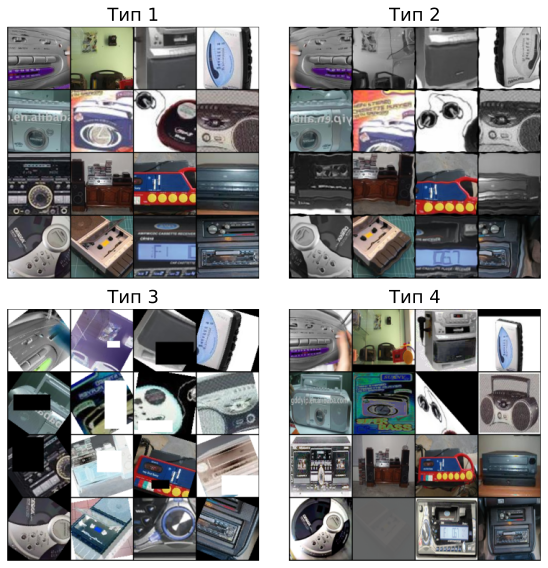

In [11]:
fig, ax = plt.subplots(2, 2, figsize=(8, 8))


for idx, (aug_name, transform) in enumerate(transforms_dict.items()):

    vis_dataset = ImageDataset(data_df=data_df, is_train=True, transform=transform)
    vis_dataloader = DataLoader(vis_dataset, batch_size=16, shuffle=False, num_workers=0)
    batch = next(iter(vis_dataloader))

    img_grid = torchvision.utils.make_grid(batch[0], nrow=4)

    ax[idx // 2, idx % 2].imshow(img_grid.permute(1, 2, 0).detach().cpu().numpy())
    ax[idx // 2, idx % 2].axis('off')
    ax[idx // 2, idx % 2].set_title(aug_name, fontsize=18)

plt.tight_layout()
plt.show()

<font color='Orange'>**Вопрос:**</font> Какой будет вывод, если запустить ячейку выше повторно? Почему это плохо?

#### Подготовка данных к обучению

Выберем минимальный набор аугментаций для нашей задачи. Наша цель &ndash; не выбить выше качество, а написать хороший цикл обучения. Хорошим тоном является нормализация данных, ведь так нейронная сеть будет учиться быстрее. Мы будем нормализировать изображения с помощью статистик, которые посчитали по всему `ImageNet`.

`IMG_MEAN[i]` содержит среднее значение пикселей для `i` канала.

`IMG_STD[i]` содержит стадартное отклонение пикселей для `i` канала.

In [12]:
IMG_MEAN = np.array([0.485, 0.456, 0.406])
IMG_STD  = np.array([0.229, 0.224, 0.225])

transform_train = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize(mean=IMG_MEAN, std=IMG_STD),
        transforms.RandomCrop((160, 160)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomGrayscale(p=0.1),

    ]
)

transform_val = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize(mean=IMG_MEAN, std=IMG_STD),
        transforms.CenterCrop((160, 160))
    ]
)

<font color='Orange'>**Вопрос:**</font> Почему преобразования для `train` и `val` разные?

In [13]:
train_dataset = ImageDataset(data_df, is_train=True,  transform=transform_train)
valid_dataset = ImageDataset(data_df, is_train=False, transform=transform_val)

len(train_dataset), len(valid_dataset)

(9469, 3925)

In [15]:
#vis_dataloader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=8)
vis_dataloader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=0)
batch = next(iter(vis_dataloader))

print(f"Размерность батча: {batch[0].shape}")
print(f"Классы в батче: {batch[1]}")

Размерность батча: torch.Size([16, 3, 160, 160])
Классы в батче: tensor([5, 9, 0, 9, 1, 9, 0, 9, 4, 0, 7, 3, 8, 9, 2, 7])


Обязательно посмотрим на данные и как они выглядят после аугментаций. Иногда при **неправильных** аугментациях можно испортить изображение.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


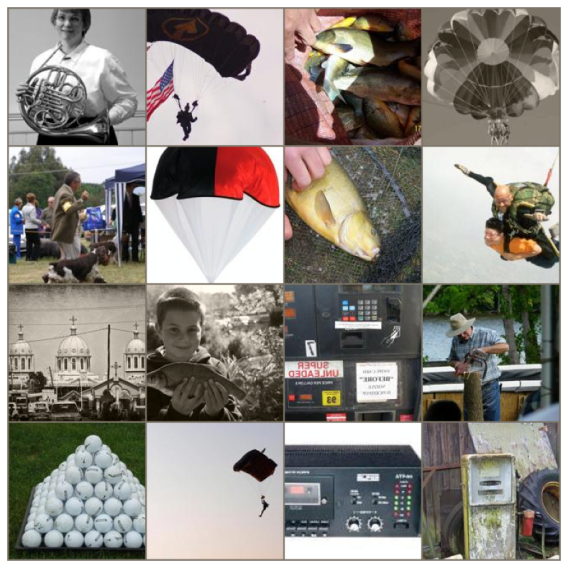

In [16]:
img_grid = torchvision.utils.make_grid(batch[0], nrow=4)

plt.figure(figsize=(8, 8))
plt.imshow(img_grid.permute(1, 2, 0).detach().cpu().numpy() * IMG_STD + IMG_MEAN)
plt.axis('off')

plt.tight_layout()
plt.show()

Мы удостверились, что данные корректны, поэтому перейдем к написанию цикла обучения.

### Цикл обучения

Выше мы описали все необходимое для правильной и аккуратной работы с данными, а именно создали `Dataset` с изображениями и аугментациями, который используется для `Dataloader`. Благодаря этому мы можем не думать о работе с данными, а эффективно итерироаться по батчам.

Нам осталось определить:

- `нейронную сеть` &ndash; то, что будет обучаться;

- `оптимизатор` &ndash; то, как будет обучаться;

- `функцию потерь` &ndash; то, по чему будем обучаться.

После этого мы сможем написать **цикл обучения**, в котором соединим все вместе.

####  LeNet для классификации

[Le et al., 1998](https://ieeexplore.ieee.org/abstract/document/726791) | примерно 80 тысяч цитат

Мы будем использовать свёрточные архитектуры, в частности реализуем что-то похожее на стандартную сеть `LeNet`. Мы могли бы начать с более сложных сетей, но у нас нет необходимости получить высокое качество.

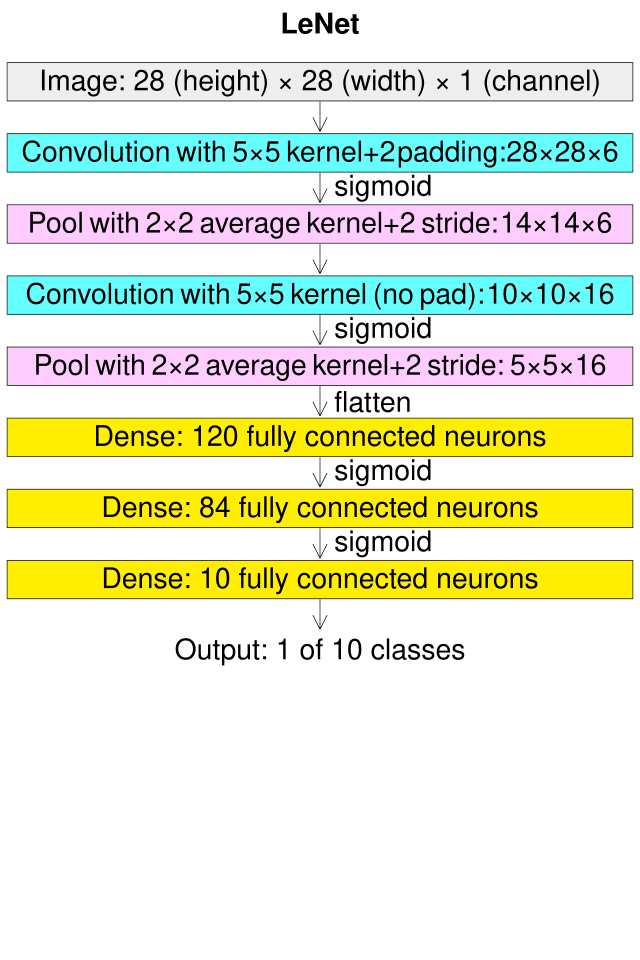

[Источник](https://deepmachinelearning.ru/docs/Neural-networks/Convolutional-architectures/AlexNet-ZFnet)

In [17]:
import torch
import torch.nn as nn
import torch.optim as optim

In [91]:
if torch.cuda.is_available():
  device = 'cuda:0'
else:
  print("Мы рекомендуем использовать GPU.")
  device = 'mps'#'cpu'
device

Мы рекомендуем использовать GPU.


'mps'

Создадим класс нейронной сети LeNet, который является наследником `torch.nn.Module`. Важно не забыть про `super().__init__()`.

In [92]:
class LeNet(torch.nn.Module):
    def __init__(self, n_classes):
        super().__init__()

        self.features = torch.nn.Sequential(
            torch.nn.Conv2d(in_channels=3, out_channels=6, kernel_size=(5, 5)),
            torch.nn.MaxPool2d(kernel_size=(2, 2), stride=(2, 2)),
            torch.nn.ReLU(),

            torch.nn.Conv2d(in_channels=6, out_channels=6, kernel_size=(5, 5)),
            torch.nn.MaxPool2d(kernel_size=(2, 2), stride=(2, 2)),
            torch.nn.ReLU(),

            torch.nn.Conv2d(in_channels=6, out_channels=16, kernel_size=(5, 5)),
            torch.nn.MaxPool2d(kernel_size=(2, 2), stride=(2, 2)),
            torch.nn.ReLU(),
        )

        self.dense = torch.nn.Sequential(
            torch.nn.Flatten(),
            torch.nn.Linear(16 * 16 * 16, 120),
            torch.nn.ReLU(),
            torch.nn.Linear(120, 84),
            torch.nn.ReLU(),
            torch.nn.Linear(84, n_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.dense(x)

        return x

Проверим, что мы не ошиблись в размерностях. Самой первой проверкой является создание прямого прохода для случайного батча.

In [93]:
net = LeNet(n_classes=10)

batch = next(iter(vis_dataloader))
out = net(batch[0])

print(f"Размерность выхода: {out.shape}")

Размерность выхода: torch.Size([16, 10])


Посмотрим на число параметров, чтобы примерно оценить сложность модели.

In [94]:
def print_params_count(model):

    total_params = sum(p.numel() for p in model.parameters())
    total_params_grad = sum(p.numel() for p in model.parameters() if p.requires_grad)

    model_name = model.__class__.__name__
    print(f"Информация о числе параметров модели: {model_name}")
    print(f"Всего параметров: \t\t {total_params}")
    print(f"Всего обучаемых параметров: \t {total_params_grad}")
    print()

In [95]:
print_params_count(net)

Информация о числе параметров модели: LeNet
Всего параметров: 		 506432
Всего обучаемых параметров: 	 506432



В качестве оптимизатора возьмем `Adam`, который является стандартом области.

In [96]:
optimizer = optim.Adam(net.parameters(), lr=1e-4)

Так как мы решаем задачу классификации, то будем использовать `torch.nn.CrossEntropyLoss()`.

In [97]:
loss_fn = torch.nn.CrossEntropyLoss()

In [98]:
train_dataloader = DataLoader(
    train_dataset,
    batch_size  = 256,
    shuffle     = True,
    drop_last   = True,
    num_workers = 0,
)

valid_dataloader = DataLoader(
    valid_dataset,
    batch_size  = 4096,
    shuffle     = False,
    num_workers = 0
)

Наконец-то мы можем написать **наш первый цикл обучения (train loop)**! Напомним его структуру:

1. Получение батча данных из датасета;
2. Вычисление нейронной сети на батче данных;
3. Вычсиление функции ошибок;
4. Рассчёт градиентов с помощью обратного распространения (backpropagation);
5. Шаг оптимизации;
6. Переход на пункт 1.

In [99]:
def train_base(epoch_num, net, optimizer, loss_fn, train_dataloader, device):

    ### YOUR CODE HERE

    global_step = 0
    net = net.to(device)
    net.train()

    for _ in tqdm(range(epoch_num)):

        for X_batch, y_true in train_dataloader:
            optimizer.zero_grad()

            X_batch = X_batch.to(device)
            y_true = y_true.to(device)

            out = net(X_batch)

            loss = loss_fn(out, y_true)
            loss.backward()

            optimizer.step()

            y_pred = torch.argmax(out, 1)
            accuracy = torch.sum(y_pred == y_true) / y_pred.shape[0]
            print(f"{global_step}, loss = {loss.item():0.3f}, \t accuracy = {accuracy.item():0.4f}")

            global_step += 1



Обучим 1 эпоху, чтобы проверить корректность работы. Если мы нигде не ошиблись, то функция потерь (loss) должна стать меньше, а точность (accuracy) выше.

In [100]:

epoch_num = 1
train_base(
    epoch_num=epoch_num,
    net=net,
    optimizer=optimizer,
    loss_fn=loss_fn,
    train_dataloader=train_dataloader,
    device=device
)

  0%|          | 0/1 [00:00<?, ?it/s]

0, loss = 2.304, 	 accuracy = 0.0859
1, loss = 2.311, 	 accuracy = 0.1133
2, loss = 2.292, 	 accuracy = 0.1445
3, loss = 2.296, 	 accuracy = 0.1133
4, loss = 2.295, 	 accuracy = 0.1289
5, loss = 2.302, 	 accuracy = 0.0820
6, loss = 2.298, 	 accuracy = 0.1133
7, loss = 2.298, 	 accuracy = 0.1328
8, loss = 2.299, 	 accuracy = 0.1094
9, loss = 2.296, 	 accuracy = 0.0898
10, loss = 2.290, 	 accuracy = 0.1172
11, loss = 2.293, 	 accuracy = 0.0938
12, loss = 2.285, 	 accuracy = 0.1211
13, loss = 2.294, 	 accuracy = 0.0703
14, loss = 2.295, 	 accuracy = 0.1211
15, loss = 2.287, 	 accuracy = 0.1133
16, loss = 2.297, 	 accuracy = 0.1406
17, loss = 2.296, 	 accuracy = 0.0859
18, loss = 2.281, 	 accuracy = 0.1523
19, loss = 2.294, 	 accuracy = 0.1562
20, loss = 2.287, 	 accuracy = 0.1523
21, loss = 2.276, 	 accuracy = 0.2305
22, loss = 2.286, 	 accuracy = 0.1602
23, loss = 2.277, 	 accuracy = 0.1875
24, loss = 2.271, 	 accuracy = 0.2617
25, loss = 2.263, 	 accuracy = 0.2734
26, loss = 2.278, 	 ac

100%|██████████| 1/1 [00:19<00:00, 19.66s/it]

35, loss = 2.242, 	 accuracy = 0.2227


Судя по выводу, модель учится: точность растет, функция потерь уменьшается. Обрати внимание, что у нас 10 классов, а точность предсказания $\sim$ 16%, что выше случайного угадывания (10%).


Такой вывод не позволит понять, что происходит с моделью при тысячах итераций, так как можно будет легко запутаться.

<font color='Orange'>**Вопрос:**</font> Как улучшить вывод модели?

Для ответа на этот вопрос, мы воспользуемся библиотеками для логирования (`tensorboard`, `wandb`, `comet_ml`, `trackio`, `ml_flow`). В этом ноутбуке мы рассмотрим `comet_ml` как наиболее комфортный логер в использовании.

### Логирование

#### Основы логирования

Мы будем использовать библиотеку `comet_ml`. Большинство логеров имеют схожий синтаксис и возможности. Мы рекомендуем попробовать `wandb`, код ниже для него закоментирован. `wandb` более известный и удобный логер, но у тебя может вознкнуть необходимость в сторонних сервисах для комфортного использования.

Библиотеки для логирования созданы с целью простого отслеживания метрик и результатов экспериментов. Опишем основные функции от очевидных до более неожиданных:

- Логирование чисел
- Логирование рисунков
- Логирование на удаленный сервер
- Логироварние архитектуры
- Сохранение файлов
- Сохранение  состояний git
- Визуализация модели
- Построение графов гиперпараметров
- Автоматический поиск гиперепараметров и их визуализация


[Подробная документация comet_ml](https://www.comet.com/docs/v2/api-and-sdk/python-sdk/overview/).

[Подробная документация wandb](https://docs.wandb.ai/) может не работать без сторонних сервисов.

In [101]:
!pip install comet_ml -q

    scikit-learn (>=1.0.*) ; extra == 'pipelines'
                  ~~~~~~^


In [102]:
#import wandb
import comet_ml

При первом запуске тебе потребуется указать API-ключ, его можно получить, если зарегистрироваться на официальном сайте.  Для логирования кода в `wandb` достаточно указать `save_code=True`.

[По ссылке](https://wandb.ai/3145tttt/cnn_mmp_2025/overview) можно посмотреть логи `wandb` для всех экспериментов.

[По ссылке](https://www.comet.com/enteralt/cnn-mmp-2025/view/new/panels) можно посмотреть логи `comet_ml` для всех экспериментов.

Для начала нужно инициализировать запуск. Ниже мы создали запуск, указали его имя (если не указать явно, то будет случайное имя), сохранили гипер параметры, сохранили код. Это базовый минимум, который нужно сделать в хорошем проекте при инициализации логера.

In [103]:
# Использовать если на GoogleColab, иначе подставить свой api
# from google.colab import userdata

In [ ]:
project_name = 'testing_2025'
run_name = 'test'
config = {"conf": "testing"}
userdata={'COMET_API_KEY':'*********'}
experiment = comet_ml.start(
  api_key=userdata.get('COMET_API_KEY'),
  project_name=project_name
)

experiment.set_name(run_name)
experiment.log_parameters(config)

for path in os.listdir('./'):
    if path.endswith('.ipynb'):
        experiment.log_code(file_name=path)

# wandb version

# run = wandb.init(
#     project=project_name,
#     name=run_name,
#     config=config,
#     save_code=True
# )

# wandb.run.log_code(
#     "./",
#     include_fn=lambda path: path.endswith(".ipynb")
# )

COMET WARNING: Ending the running experiment and creating a new Experiment because:
api_key doesn't match ('BMQDd********************' != '1')


COMET WARNING: To get all data logged automatically, import comet_ml before the following modules: sklearn, torch.
COMET WARNING: As you are running in a Jupyter environment, you will need to call `experiment.end()` when finished to ensure all metrics and code are logged before exiting.
COMET INFO: Experiment is live on comet.com https://www.comet.com/dmitri-churikov/testing-2025/9f6630263b7b4a6086f232c801132403



Логирование чисел.

In [107]:
experiment.log_metrics({"train/loss": 0, "eval/loss": 0}, step=0)

# wandb version
# wandb.log({"train/loss": 0, "eval/loss": 0}, step=0)

**Важно:** Параметр `step` должен расти монотонно!

Логирование изображений. Важно не забывать про нормализацию изображений при логировании.

In [108]:
experiment.log_image(image_data=transforms.functional.to_pil_image(img_grid), name="media/img", step=0)

# wandb version
# wandb.log({"media/img": wandb.Image(img_grid)}, step=0)

{'web': 'https://www.comet.com/api/image/download?imageId=b92e06db1f124a00874699196d75c866&experimentKey=9f6630263b7b4a6086f232c801132403',
 'api': 'https://www.comet.com/api/rest/v1/image/get-image?imageId=b92e06db1f124a00874699196d75c866&experimentKey=9f6630263b7b4a6086f232c801132403',
 'imageId': 'b92e06db1f124a00874699196d75c866'}

Логирование гистограмм

In [109]:
experiment.log_histogram_3d(values=torch.arange(100) ** 2, name='media/hist', step=0)


# wandb version
# wandb.log({"media/hist": wandb.Histogram(torch.arange(100) ** 2)}, step=0)

{'web': 'https://www.comet.com/api/asset/download?assetId=93328b321936418ab35e87be2aeff957&experimentKey=9f6630263b7b4a6086f232c801132403',
 'api': 'https://www.comet.com/api/rest/v2/experiment/asset/get-asset?assetId=93328b321936418ab35e87be2aeff957&experimentKey=9f6630263b7b4a6086f232c801132403',
 'assetId': '93328b321936418ab35e87be2aeff957'}

Логирование графиков.

In [110]:
fig = plt.figure(figsize=(6,6))
plt.plot(np.arange(100) ** 2)
plt.title(r"$y = x^2$")

experiment.log_figure(figure=fig, figure_name='media/plots', step=0)

# wandb version
# wandb.log({"media/plots": wandb.Image(fig)}, step=0)

plt.close('all') # мы не хотим отображать графики в ноутбуке

Посмотрим на запуск, в нем должны отобразиться логированные метрики. Иногда метрики логируются не сразу, а после заполнения некого буффера, так как синхронизация с веб сайтом &ndash; дорогая операция.

In [111]:
experiment.log_metrics({"train/loss": 2, "eval/loss": 1}, step=1)
experiment.log_metrics({"train/loss": 5, "eval/loss": -1}, step=2)

fig = plt.figure(figsize=(6,6))
plt.plot(np.arange(100) ** 3)
plt.title(r"$y = x^3$")

experiment.log_figure(figure=fig, figure_name='media/plots', step=3)
experiment.log_histogram_3d(values=torch.arange(100) ** 3, name='media/hist', step=3)


# Следующие шаги для визаулизаций wandb
# wandb.log({"train/loss": 2, "eval/loss": 1}, step=1)
# wandb.log({"media/hist": wandb.Histogram(torch.arange(100) ** 3)}, step=1)

# fig = plt.figure(figsize=(6,6))
# plt.plot(np.arange(100) ** 3)
# plt.title(r"$y = x^3$")

# wandb.log({"media/plots": wandb.Image(fig)}, step=1)

# # Сравнить в чем отличие
# wandb.log({"media/img": wandb.Image(img_grid.permute(1, 2, 0).numpy() / 4 - 1)}, step=1)
# wandb.log({"media/img": wandb.Image(img_grid / 4)}, step=2)


plt.close('all') # мы не хотим отображать графики в ноутбуке

Обязательно нужно завершить запуск.

In [112]:
experiment.end()

# wandb version
# wandb.finish()

COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO: Comet.ml Experiment Summary
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO:   Data:
COMET INFO:     display_summary_level : 1
COMET INFO:     name                  : test
COMET INFO:     url                   : https://www.comet.com/dmitri-churikov/testing-2025/9f6630263b7b4a6086f232c801132403
COMET INFO:   Metrics [count] (min, max):
COMET INFO:     eval/loss [3]  : (-1, 1)
COMET INFO:     train/loss [3] : (0, 5)
COMET INFO:   Others:
COMET INFO:     Name : test
COMET INFO:   Parameters:
COMET INFO:     conf : testing
COMET INFO:   Uploads:
COMET INFO:     environment details      : 1
COMET INFO:     figures                  : 2
COMET INFO:     filename                 : 1
COMET INFO:     git metadata             : 1
COMET INFO:     git-patch (uncompressed) : 1 (824 bytes)
COMET INFO:     histogram3d            

У `wandb` есть неочевидные преимущества:

1. при отображении графиков на сайте, можно отобразить все точки, а в `comet_ml` не более 1000 (по умолчанию 50);

2. `wandb` лучше работает с изображениями и нормализует их автоматически;

3. для логирования `wandb` достаточно обращать к глобальной переменной `wandb`. В случае `comet_ml` нужно использовать локальную переменную `experiment`. Обойти это можно с помощью команды `comet_ml.get_running_experiment()`.

4. `wandb` не требует уточнения типа данных при логировании, всё логируется через `wandb.log`.

#### Добавление логирования в цикл обучения.

In [113]:
def train_loger(epoch_num, net, optimizer, loss_fn, train_dataloader, device, run_name):

    # ДОБАВИЛИ
    experiment = comet_ml.start(
      api_key=userdata.get('COMET_API_KEY'),
      project_name="cnn_mmp_2025"
    )
    experiment.set_name(run_name)
    for path in os.listdir('./'):
        if path.endswith('.ipynb'):
            experiment.log_code(file_name=path)


    # wandb.init(
    #     project="cnn_mmp_2025",
    #     name=run_name,
    #     save_code=True
    # )
    # wandb.run.log_code(
    #     "./",
    #     include_fn=lambda path: path.endswith(".ipynb")
    # )

    global_step = 0
    net = net.to(device)

    for _ in tqdm(range(epoch_num)):
        net.train()

        for X_batch, y_true in train_dataloader:
            optimizer.zero_grad()

            X_batch = X_batch.to(device)
            y_true = y_true.to(device)

            out = net(X_batch)

            loss = loss_fn(out, y_true)
            loss.backward()

            optimizer.step()

            y_pred = torch.argmax(out, 1)
            accuracy = torch.sum(y_pred == y_true) / y_pred.shape[0]

            # ДОБАВИЛИ
            experiment.log_metrics({"train/loss": loss.item(), "train/accuracy": accuracy.item()}, step=global_step)
            # wandb.log({"train/loss": loss.item(), "train/accuracy": accuracy.item()}, step=global_step)

            global_step += 1

    # ДОБАВИЛИ
    experiment.end()
    # wandb.finish()

<font color='Orange'>**Вопрос:**</font>  Можно ли сразу запустить обучение? Например, сразу запустить код ниже.

In [114]:
# epoch_num = 1
# train_loger(epoch_num, net, optimizer, loss_fn, train_dataloader, valid_dataloader, device, run_name="LeNet_base")

In [115]:
net = LeNet(10)
optimizer = optim.Adam(net.parameters(), lr=1e-4)

In [116]:
epoch_num = 10

train_loger(
    epoch_num=epoch_num,
    net=net,
    optimizer=optimizer,
    loss_fn=loss_fn,
    train_dataloader=train_dataloader,
    device=device,
    run_name="LeNet_base"
)

COMET WARNING: To get all data logged automatically, import comet_ml before the following modules: sklearn, torch.
COMET WARNING: As you are running in a Jupyter environment, you will need to call `experiment.end()` when finished to ensure all metrics and code are logged before exiting.
COMET INFO: Experiment is live on comet.com https://www.comet.com/dmitri-churikov/cnn-mmp-2025/585750cdfb9c48d683402f5b00c9adb7

100%|██████████| 10/10 [02:30<00:00, 15.08s/it]
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO: Comet.ml Experiment Summary
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO:   Data:
COMET INFO:     display_summary_level : 1
COMET INFO:     name                  : LeNet_base
COMET INFO:     url                   : https://www.comet.com/dmitri-churikov/cnn-mmp-2025/585750cdfb9c48d683402f5b00c9adb7
COMET INFO:   Metrics [count] (min, max):
COMET INFO:     

COMET ERROR: File upload failed: FileNotFoundError(2, 'No such file or directory'), file: /var/folders/zv/qxndkm_x6bs0p2gqyfzltkg00000gq/T/tmp0vf81wha/tmpnxx14hbd, url: 'https://www.comet.com/clientlib/asset/upload', max retries: 4


<font color='Orange'>**Вопрос:**</font> Чего не хватает?

### Валидация

Обычно, модель выбирают по метрикам на валидационной выборке. Кроме того, валидация &ndash; хороший способ заметить переобучение. Без валидации мы ничего не знаем о качестве модели.

In [117]:
@torch.no_grad()
def evaluate(net, valid_dataloader, loss_fn, device):

    ### YOUR CODE HERE

    net.eval()
    loss, accuracy = 0, 0
    count = 0
    for X_batch, y_true in valid_dataloader:
        X_batch = X_batch.to(device)
        y_true = y_true.to(device)

        out = net(X_batch)
        y_pred = torch.argmax(out, 1)

        bs = out.shape[0]
        loss += loss_fn(out, y_true).item() * bs
        accuracy += torch.sum(y_pred == y_true).item()
        count += bs

    return loss / count, accuracy / count

<font color='Orange'>**Вопрос:**</font> Что делает декоратор torch.no_grad?

In [118]:
def train_loger_eval(epoch_num, net, optimizer, loss_fn, train_dataloader, valid_dataloader, device, run_name):

    experiment = comet_ml.start(
      api_key=userdata.get('COMET_API_KEY'),
      project_name="cnn_mmp_2025"
    )
    experiment.set_name(run_name)
    for path in os.listdir('./'):
        if path.endswith('.ipynb'):
            experiment.log_code(file_name=path)


    # wandb.init(
    #     project="cnn_mmp_2025",
    #     name=run_name,
    #     save_code=True
    # )
    # wandb.run.log_code(
    #     "./",
    #     include_fn=lambda path: path.endswith(".ipynb")
    # )

    global_step = 0
    net = net.to(device)

    for _ in tqdm(range(epoch_num)):
        net.train()

        for X_batch, y_true in train_dataloader:
            optimizer.zero_grad()

            X_batch = X_batch.to(device)
            y_true = y_true.to(device)

            out = net(X_batch)

            loss = loss_fn(out, y_true)
            loss.backward()

            optimizer.step()

            y_pred = torch.argmax(out, 1)
            accuracy = torch.sum(y_pred == y_true) / y_pred.shape[0]

            experiment.log_metrics({"train/loss": loss.item(), "train/accuracy": accuracy.item()}, step=global_step)
            # wandb.log({"train/loss": loss.item(), "train/accuracy": accuracy.item()}, step=global_step)

            global_step += 1

        # ДОБАВИЛИ
        loss, accuracy = evaluate(
            net=net,
            valid_dataloader=valid_dataloader,
            loss_fn=loss_fn,
            device=device
            )
        experiment.log_metrics({"eval/loss": loss, "eval/accuracy": accuracy}, step=global_step)
        # wandb.log({"eval/loss": loss, "eval/accuracy": accuracy}, step=global_step)

    experiment.end()
    # wandb.finish()

In [119]:
net = LeNet(10)
optimizer = optim.Adam(net.parameters(), lr=1e-4)

In [120]:
epoch_num = 10
train_loger_eval(
    epoch_num        = epoch_num,
    net              = net,
    optimizer        = optimizer,
    loss_fn          = loss_fn,
    train_dataloader = train_dataloader,
    valid_dataloader = valid_dataloader,
    device           = device,
    run_name         = "LeNet_eval"
)

COMET WARNING: To get all data logged automatically, import comet_ml before the following modules: sklearn, torch.
COMET WARNING: As you are running in a Jupyter environment, you will need to call `experiment.end()` when finished to ensure all metrics and code are logged before exiting.
COMET WARNING: Failed to check backend version at URL: 'https://www.comet.com/clientlib/isAlive/ver', reason: HTTPSConnectionPool(host='www.comet.com', port=443): Max retries exceeded with url: /clientlib/isAlive/ver (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x168c2aeb0>: Failed to establish a new connection: [Errno 8] nodename nor servname provided, or not known'))
COMET ERROR: Failed to establish a connection to Comet server. Please check your internet connection. Your experiment will not be logged 
For more details, please refer to: https://www.comet.com/docs/v2/api-and-sdk/python-sdk/warnings-errors/
100%|██████████| 10/10 [03:30<00:00, 21.09s/it]


<font color='Orange'>**Вопрос:**</font> Чего не хватает?

### Кризис воспроизводимости


Выше мы могли заметить, что обучение сильно меняется от запуска к запуску, что создает следующие проблемы:

- Возможно, кто-то другой не сможет воспроизвести твои результаты

- Возможно, **ты** никогда не сможешь воспроизвести свои же результаты

Получить крутую модель, но без возможности повторения, крайне плохо для науки, индустрии, домашней работы и просто грустно. Для воспроизводимых результатов недостаточно просто зафикисировать `seed`. Например, ниже продемонстрирована зависимость генератора случайных чисел от устройства.


**Важно:** Невоспроизводимая работа **не** имеет ценности!

In [121]:
torch.manual_seed(42)
randn1 = torch.randn(10)

torch.manual_seed(42)
randn2 = torch.randn(10)

randn1, randn2

(tensor([ 0.3367,  0.1288,  0.2345,  0.2303, -1.1229, -0.1863,  2.2082, -0.6380,
          0.4617,  0.2674]),
 tensor([ 0.3367,  0.1288,  0.2345,  0.2303, -1.1229, -0.1863,  2.2082, -0.6380,
          0.4617,  0.2674]))

In [122]:
torch.manual_seed(42)
randn1 = torch.randn(10)

torch.manual_seed(42)
#randn2 = torch.randn(10, device='cuda')
randn2 = torch.randn(10)


randn1, randn2

(tensor([ 0.3367,  0.1288,  0.2345,  0.2303, -1.1229, -0.1863,  2.2082, -0.6380,
          0.4617,  0.2674]),
 tensor([ 0.3367,  0.1288,  0.2345,  0.2303, -1.1229, -0.1863,  2.2082, -0.6380,
          0.4617,  0.2674]))

Для начала постараемся сделать обучение независимым от очередности запуска, воспользуемся советами из официальной статьи [Reproducibilty PyTorch](https://pytorch.org/docs/stable/notes/randomness.html). Нам необходимо:

- Зафиксировать сид CPU;
- Зафиксировать сид GPU;
- Зафиксировать сид `numpy`;
- Зафиксировать сид стандартного random;

В целом, этого уже будет достаточно и намного лучше, чем в большинстве современных работ. Малой кровью можно зафиксировать DataLoader, такое тоже будет полезно. Кроме того, существуют рандомизированные алгоритмы и алгоритмы, зависимые от модели технического оборудования. Эту случайность намного сложнее контролировать, но можно с помощью `torch.use_deterministic_algorithms(True)` &ndash;так гарантируется точная воспроизводимость, но код замедлится, скорее всего.


На практике можно почти все случайности зафиксировать и гарантировать детерминизм. Откуда возникает вопрос: "Будет ли хорошей модель, которая перестает учиться, если чуть иначе зашафлить датасет или чуть иначе умножать матрицы?"

In [123]:
def set_global_seed(seed: int) -> None:
    """Set global seed for reproducibility.
    :param int seed: Seed to be set
    """


    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    # если нужно гарантировать 1000% воспроизводимость
    # torch.use_deterministic_algorithms(False)

    # Для Dataloader
    g = torch.Generator()
    g.manual_seed(seed)

    return g

# Для каждого worker в Dataloader
def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)


<font color='Orange'>**Вопрос:**</font> Где ошибка в коде ниже?

In [124]:
# net = LeNet(10)
# optimizer = optim.Adam(net.parameters(), lr=1e-4)

# g = set_global_seed(42)

# train_dataloader = DataLoader(
#     train_dataset,
#     batch_size     = 256,
#     shuffle        = True,
#     drop_last      = True,
#     num_workers    = 0,
#     worker_init_fn = seed_worker,
#     generator      = g
# )

# valid_dataloader = DataLoader(
#     valid_dataset,
#     batch_size    = 4096,
#     shuffle       = False,
#     num_workers   = 4
# )

# epoch_num = 10
# train_loger_eval(
#     epoch_num        = epoch_num,
#     net              = net,
#     optimizer        = optimizer,
#     loss_fn          = loss_fn,
#     train_dataloader = train_dataloader,
#     valid_dataloader = valid_dataloader,
#     device           = device,
#     run_name         = "LeNet_seed"
# )

In [125]:
g = set_global_seed(42)

train_dataloader = DataLoader(
    train_dataset,
    batch_size     = 256,
    shuffle        = True,
    drop_last      = True,
    num_workers    = 0,
    worker_init_fn = seed_worker,
    generator      = g
)

valid_dataloader = DataLoader(
    valid_dataset,
    batch_size    = 4096,
    shuffle       = False,
    num_workers   = 0
)

net = LeNet(10)
optimizer = optim.Adam(net.parameters(), lr=1e-4)

In [126]:
epoch_num = 10
train_loger_eval(
    epoch_num        = epoch_num,
    net              = net,
    optimizer        = optimizer,
    loss_fn          = loss_fn,
    train_dataloader = train_dataloader,
    valid_dataloader = valid_dataloader,
    device           = device,
    run_name         = "LeNet_seed"
)

COMET WARNING: To get all data logged automatically, import comet_ml before the following modules: sklearn, torch.
COMET WARNING: As you are running in a Jupyter environment, you will need to call `experiment.end()` when finished to ensure all metrics and code are logged before exiting.
COMET WARNING: Failed to check backend version at URL: 'https://www.comet.com/clientlib/isAlive/ver', reason: HTTPSConnectionPool(host='www.comet.com', port=443): Max retries exceeded with url: /clientlib/isAlive/ver (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x168c6a6d0>: Failed to establish a new connection: [Errno 8] nodename nor servname provided, or not known'))
COMET ERROR: Failed to establish a connection to Comet server. Please check your internet connection. Your experiment will not be logged 
For more details, please refer to: https://www.comet.com/docs/v2/api-and-sdk/python-sdk/warnings-errors/
100%|██████████| 10/10 [18:34<00:00, 111.43s/it] 


<font color='Orange'>**Вопрос:**</font> Чего не хватает?

### Дополнительные логи

Очень часто на практике обучение в какой-то момент просто ломается. Причины бывают разные и чем сложнее твоя модель и задача, тем более разные причины. Возможно, где-то численная нестабильность, возможно, засэмплировался странный батч. Для этого бывает полезно логировать **веса** и **градиенты** параметров.

Логирование градиентов также позволит отслеживать затухание или взрывы, что часто бывает полезно.

In [127]:
@torch.no_grad()
def log_gradients(model, global_step, log_norm=True, log_hist=True):
    exp = comet_ml.get_running_experiment()

    for tag, value in model.named_parameters():
        g = value.grad
        if g is None:
            continue

        if log_hist:
            experiment.log_histogram_3d(values=g.cpu(), name=f'grad/{tag}', step=global_step)
            # wandb.log({f"grad/{tag}": wandb.Histogram(g.cpu())}, global_step)

        if log_norm:
            experiment.log_metrics({f'grad_norm/{tag}': torch.norm(g.cpu())}, step=global_step)
            # wandb.log({f"grad_norm/{tag}": torch.norm(g.cpu())}, global_step)

@torch.no_grad()
def log_weights(model, global_step, log_norm=True, log_hist=True):
    exp = comet_ml.get_running_experiment()

    for tag, value in model.named_parameters():
        g = value.grad
        if g is None:
            continue

        if log_hist:
            experiment.log_histogram_3d(values=value.cpu(), name=f'weight/{tag}', step=global_step)
            # wandb.log({f"weight/{tag}": wandb.Histogram(value.cpu())}, global_step)

        if log_norm:
            experiment.log_metrics({f'weight_norm/{tag}': torch.norm(value.cpu())}, step=global_step)
            # wandb.log({f"weight_norm/{tag}": torch.norm(value.cpu())}, global_step)

In [128]:
def train_progress(config, net, optimizer, loss_fn, train_dataloader, valid_dataloader, device):

    experiment = comet_ml.start(
      api_key=userdata.get('COMET_API_KEY'),
      project_name="cnn_mmp_2025"
    )
    experiment.set_name(config['name'])
    for path in os.listdir('./'):
        if path.endswith('.ipynb'):
            experiment.log_code(file_name=path)

    experiment.log_parameters(config) # ДОБАВИЛИ

    # wandb.init(
    #     project="cnn_mmp_2025",
    #     name=config['name'],
    #     save_code=True
    #     config=config               # ДОБАВИЛИ
    # )
    # wandb.run.log_code(
    #     "./",
    #     include_fn=lambda path: path.endswith(".ipynb")
    # )

    global_step = 0
    net = net.to(device)

    epoch_num = config['epoch_num']
    for _ in tqdm(range(epoch_num)):
        net.train()

        for X_batch, y_true in train_dataloader:
            optimizer.zero_grad()

            X_batch = X_batch.to(device)
            y_true = y_true.to(device)

            out = net(X_batch)

            loss = loss_fn(out, y_true)
            loss.backward()

            optimizer.step()

            # ДОБАВИЛИ
            log_gradients(net, global_step)
            log_weights(net, global_step)

            y_pred = torch.argmax(out, 1)
            accuracy = torch.sum(y_pred == y_true) / y_pred.shape[0]

            experiment.log_metrics({"train/loss": loss.item(), "train/accuracy": accuracy.item()}, step=global_step)
            # wandb.log({"train/loss": loss.item(), "train/accuracy": accuracy.item()}, step=global_step)

            global_step += 1

        loss, accuracy = evaluate(
            net              = net,
            valid_dataloader = valid_dataloader,
            loss_fn          = loss_fn,
            device           = device
            )
        experiment.log_metrics({"eval/loss": loss, "eval/accuracy": accuracy}, step=global_step)
        # wandb.log({"eval/loss": loss, "eval/accuracy": accuracy}, step=global_step)

    experiment.end()
    # wandb.finish()

Выше мы добавили новые логи, но также хотелось бы запоминать гиперпараметры. Например, мы увидели, что какой-то запуск выбивает очень хорошие метрики. Как ты будешь воспроизводить этот запуск? Скорее всего, на практике ты забудешь, с какими параметрами запускался твой код. Поэтому лучше сохранять все гиперпараметры внутри одного конфига. Так ты избавишься и от магических констант и повысишь воспроизводимость.

In [129]:
# ДОБАВИЛИ
config = {
    'seed'           : 42,
    'lr'             : 1e-4,
    'epoch_num'      : 10,
    'batch_size'     : 256,
    'val_batch_size' : 4096,
    'name'           : 'LeNet_progress'
}

g = set_global_seed(config['seed'])

train_dataloader = DataLoader(
    train_dataset,
    batch_size     = config['batch_size'],
    shuffle        = True,
    drop_last      = True,
    num_workers    = 0,
    worker_init_fn = seed_worker,
    generator      = g
)

valid_dataloader = DataLoader(
    valid_dataset,
    batch_size    = config['val_batch_size'],
    shuffle       = False,
    num_workers   = 0
)


net = LeNet(10)
optimizer = optim.Adam(net.parameters(), lr=config['lr'])

In [130]:
train_progress(
    config           = config,
    net              = net,
    optimizer        = optimizer,
    loss_fn          = loss_fn,
    train_dataloader = train_dataloader,
    valid_dataloader = valid_dataloader,
    device           = device
)

COMET WARNING: To get all data logged automatically, import comet_ml before the following modules: sklearn, torch.
COMET WARNING: As you are running in a Jupyter environment, you will need to call `experiment.end()` when finished to ensure all metrics and code are logged before exiting.
COMET WARNING: Failed to check backend version at URL: 'https://www.comet.com/clientlib/isAlive/ver', reason: HTTPSConnectionPool(host='www.comet.com', port=443): Max retries exceeded with url: /clientlib/isAlive/ver (Caused by ConnectTimeoutError(<urllib3.connection.HTTPSConnection object at 0x165ba8b50>, 'Connection to www.comet.com timed out. (connect timeout=10)'))
COMET INFO: Experiment is live on comet.com https://www.comet.com/dmitri-churikov/cnn-mmp-2025/2b0f0f4df2c64314adc95a51e3bad670

100%|██████████| 10/10 [04:37<00:00, 27.76s/it]
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO: Comet.ml Experiment Summary
COMET INFO: -----------

<font color='Orange'>**Вопрос:**</font> Чего не хватает?

### Чекпоинты

Обучение модели занимает много времени и ресурсов, но обычно модели учат не ради высокой метрики на валидации, а ради дальнейшего использования. Для того, чтобы использовать модель в будущем, нужно явно прописать сохранения. Сохранять можно либо каждые `N` итераций, либо по метрике на валидации. Файл, в котором содержатся веса модели и иная важная информация об обучении, называется **чекпоинтом** (точка сохранения).

- Обучить модель &ndash; хорошо.
- Обучить модель и получить воспроизводимые результаты &ndash; отлично
- Обучить модель и получить воспроизводимые результаты, и сохранить веса &ndash; **идеально**

In [131]:
def train_final(config, net, optimizer, loss_fn, train_dataloader, valid_dataloader, device):


    experiment = comet_ml.start(
      api_key='BMQDdAsJKBdqwJILPDmftz5kN',#userdata.get('COMET_API_KEY'),
      project_name="cnn_mmp_2025"
    )
    experiment.set_name(config['name'])
    for path in os.listdir('./'):
        if path.endswith('.ipynb'):
            experiment.log_code(file_name=path)

    experiment.log_parameters(config)

    # wandb.init(
    #     project="cnn_mmp_2025",
    #     name=config['name'],
    #     save_code=True
    #     config=config
    # )
    # wandb.run.log_code(
    #     "./",
    #     include_fn=lambda path: path.endswith(".ipynb")
    # )

    global_step = 0
    net = net.to(device)

    # ДОБАВИЛИ
    best_accuracy = 0
    os.makedirs(config['checkpoint_dir'], exist_ok=True)

    epoch_num = config['epoch_num']
    for epoch in tqdm(range(epoch_num)):
        net.train()

        for X_batch, y_true in train_dataloader:
            optimizer.zero_grad()

            X_batch = X_batch.to(device)
            y_true = y_true.to(device)

            out = net(X_batch)

            loss = loss_fn(out, y_true)
            loss.backward()

            optimizer.step()

            log_gradients(net, global_step)
            log_weights(net, global_step)

            y_pred = torch.argmax(out, 1)
            accuracy = torch.sum(y_pred == y_true) / y_pred.shape[0]

            experiment.log_metrics({"train/loss": loss.item(), "train/accuracy": accuracy.item()}, step=global_step)
            # wandb.log({"train/loss": loss.item(), "train/accuracy": accuracy.item()}, step=global_step)

            global_step += 1

        loss, accuracy = evaluate(
            net              = net,
            valid_dataloader = valid_dataloader,
            loss_fn          = loss_fn,
            device           = device
        )
        experiment.log_metrics({"eval/loss": loss, "eval/accuracy": accuracy}, step=global_step)
        # wandb.log({"eval/loss": loss, "eval/accuracy": accuracy}, step=global_step)

        # ДОБАВИЛИ
        if accuracy > best_accuracy:
            best_accuracy = accuracy
            # YOUR CODE HERE
            torch.save({
                'epoch': epoch,
                'iter': global_step,
                'model_state_dict': net.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'loss': loss,
                'metric': accuracy
                }, os.path.join(config['checkpoint_dir'], config['checkpoint_name']))

    experiment.end()
    # wandb.finish()

In [132]:
# ДОБАВИЛИ
config = {
    'seed'           : 42,
    'lr'             : 1e-4,
    'epoch_num'      : 10,
    'batch_size'     : 256,
    'val_batch_size' : 4096,
    'name'           : 'LeNet_final',
    'checkpoint_dir' : './checkpoints',
    'checkpoint_name': 'LeNet.pth'
}

g = set_global_seed(config['seed'])
g.manual_seed(0)

train_dataloader = DataLoader(
    train_dataset,
    batch_size     = config['batch_size'],
    shuffle        = True,
    drop_last      = True,
    num_workers    = 0,
    worker_init_fn = seed_worker,
    generator      = g
)

valid_dataloader = DataLoader(
    valid_dataset,
    batch_size   = config['val_batch_size'],
    shuffle      = False,
    num_workers  = 0
)


net = LeNet(10)
optimizer = optim.Adam(net.parameters(), lr=config['lr'])

In [133]:
train_final(
    config           = config,
    net              = net,
    optimizer        = optimizer,
    loss_fn          = loss_fn,
    train_dataloader = train_dataloader,
    valid_dataloader = valid_dataloader,
    device           = device
)

COMET WARNING: To get all data logged automatically, import comet_ml before the following modules: sklearn, torch.
COMET WARNING: As you are running in a Jupyter environment, you will need to call `experiment.end()` when finished to ensure all metrics and code are logged before exiting.
COMET INFO: Experiment is live on comet.com https://www.comet.com/dmitri-churikov/cnn-mmp-2025/247bcfd4314e4fdd95eb7fece92c863e

100%|██████████| 10/10 [03:42<00:00, 22.27s/it]
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO: Comet.ml Experiment Summary
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO:   Data:
COMET INFO:     display_summary_level : 1
COMET INFO:     name                  : LeNet_final
COMET INFO:     url                   : https://www.comet.com/dmitri-churikov/cnn-mmp-2025/247bcfd4314e4fdd95eb7fece92c863e
COMET INFO:   Metrics [count] (min, max):
COMET INFO:    

### Философия и немного рефлексии

<font color='Orange'>**Вопрос:**</font> Чего не хватает?

Как мы уже поняли, отвечать на этот вопрос можно бесконечно, но давай попробуем это сделать в последний раз за сегодня.

Цикл обучения отражает то, что автор считает важным. Например, очень часто блок `.zero_grad()`, `.backward()`, `.step()` помещают внутрь отдельной функции или используют готовые фреймворки:

- [PyTorch Lightning](https://lightning.ai/docs/pytorch/stable/)

- [HuggingFace trainer](https://huggingface.co/docs/transformers/main_classes/trainer)

- [PyTorch Ignit](https://pytorch.org/ignite/index.html)

В них весь цикл обучения уже записан и тебе достаточно просто передать функцию, которая по батчу считает ошибку.

**Почему же для такого простого цикла обучения кто-то пишет отдельные библиотеки?**

Выше мы рассмотрели самую простую задачу без разных инженерных особенностей, но на самом деле можно:

- Нормировать градиенты
- Использовать смешанную точность
- Аккумулировать градиенты
- Использовать распределенное обучение
- Использовать экономию памяти GPU
- ...

Все это мы будем постепенно разбирать в будущем, пока мы научились самым основам, которые позоволят идти дальше.

**Важно:** Цикл обучения в исследовательских задачах &ndash; это то, что ты делаешь для себя и самое главное, чтобы тебе было удобно. Кто-то пишет свои логгеры, а может, ты найдёшь что-то своё.

Выше мы использовали подход обучения **эпохами**, но иногда бывает полезно обучать модели **итерациями**. Например, у нас нет конкретного обучающего датасета или же датасет слишком большой. В целом, подход через итереции более универсальный и можно записать функцию `train` следующим образом:



```python
global_step = 0

for _ in tqdm(range(epoch)):
    for batch in data_loader:
        net.train()
        optim.zero_grad()
        
        loss = net(batch)
        loss.backward()
        
        optim.step()
        
        if global_step % config.eval_freq == 0:
            eval_loss = eval()
            
        if global_step % config.checkpoint_freq == 0:
            torch.save({'model': model.state_dict()}, 'checkpoint.pth')
            
        if global_step % config.whatever_freq == 0:
            ...
        
        if global_step == max_iter:
            return
        
        global_step += 1
```

### Результаты и исследование

`LeNet` &ndash; очень простая архитектура. Если мы хотим получить хорошее качество, нужно использовать что-то посложнее (например, взять модель из `torchvision.models`), а также использовать аугментацию данных. Другой путь улучшения результата &ndash; использование предобученной сети и `transfer learning`.

Мы хотим повысить качество, но пока рассмотрели только самую базовую свёрточную архитектуру. Прежде чем повысить качество, давай попробуем получить некоторый `бейзлайн` &ndash; то, с чем мы будем сравнивать результаты.

Сейчас у нас есть свёрточный `бейзлайн` &ndash; `LeNet`

Ниже мы получим полносвязный `бейзлайн` &ndash; `MLP`

Дальше мы будем обучать `ResNet18`, у которого 11 миллионов параметров, поэтому у `MLP` должно быть сравнимое количество параметров, иначе мы не сможем сделать по результатам правильные выводы.

#### MLP



In [134]:
class DeepNetwork(nn.Module):
    def __init__(self, input_dim, hidden_dims, num_classes):
        super().__init__()

        self.fc_in = nn.Sequential(
                nn.Flatten(1),
                nn.Linear(in_features=input_dim, out_features=hidden_dims[0], bias=True),
                nn.ReLU(),
            )

        self.layers = nn.Sequential(
            *[
                nn.Sequential(nn.Linear(h_in, h_out), nn.ReLU())
                for h_in, h_out in zip(hidden_dims[:-1], hidden_dims[1:])
             ],
        )

        self.fc_out = nn.Linear(hidden_dims[-1], num_classes)

    def forward(self, x):
        x = self.fc_in(x)
        x = self.layers(x)

        return self.fc_out(x)

In [135]:
print_params_count(LeNet(10))
print_params_count(DeepNetwork(input_dim=160 * 160 * 3, hidden_dims=[128, 256, 256, 128], num_classes=10))


Информация о числе параметров модели: LeNet
Всего параметров: 		 506432
Всего обучаемых параметров: 	 506432

Информация о числе параметров модели: DeepNetwork
Всего параметров: 		 9963530
Всего обучаемых параметров: 	 9963530



In [136]:
config = {
    'seed'           : 42,
    'lr'             : 1e-4,
    'epoch_num'      : 10,
    'batch_size'     : 256,
    'val_batch_size' : 4096,
    'name'           : 'MLP',
    'checkpoint_dir' : './checkpoints',
    'checkpoint_name': 'MLP.pth',
    'input_dim'      : 160 * 160 * 3,        # ДОБАВИЛИ
    'hidden_dims'    : [128, 256, 256, 128], # ДОБАВИЛИ
}
config['name'] = f"{config['name']}_{config['hidden_dims']}"

g = set_global_seed(config['seed'])
g.manual_seed(0)

train_dataloader = DataLoader(
    train_dataset,
    batch_size     = config['batch_size'],
    shuffle        = True,
    drop_last      = True,
    num_workers    = 0,
    worker_init_fn = seed_worker,
    generator      = g
)

valid_dataloader = DataLoader(
    valid_dataset,
    batch_size    = config['val_batch_size'],
    shuffle       = False,
    num_workers   = 0
)

net = DeepNetwork(
    input_dim   = config['input_dim'],
    hidden_dims = config['hidden_dims'],
    num_classes = 10
    )
optimizer = optim.Adam(net.parameters(), lr=config['lr'])

In [137]:
train_final(
    config           = config,
    net              = net,
    optimizer        = optimizer,
    loss_fn          = loss_fn,
    train_dataloader = train_dataloader,
    valid_dataloader = valid_dataloader,
    device           = device
)

COMET WARNING: To get all data logged automatically, import comet_ml before the following modules: sklearn, torch.
COMET WARNING: As you are running in a Jupyter environment, you will need to call `experiment.end()` when finished to ensure all metrics and code are logged before exiting.
COMET INFO: Experiment is live on comet.com https://www.comet.com/dmitri-churikov/cnn-mmp-2025/cbefda744e1c49a7a835771e5c09013e

100%|██████████| 10/10 [04:50<00:00, 29.07s/it]
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO: Comet.ml Experiment Summary
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO:   Data:
COMET INFO:     display_summary_level : 1
COMET INFO:     name                  : MLP_[128, 256, 256, 128]
COMET INFO:     url                   : https://www.comet.com/dmitri-churikov/cnn-mmp-2025/cbefda744e1c49a7a835771e5c09013e
COMET INFO:   Metrics [count] (min, max):
CO

#### Бейзлан: обучение resnet18 с нуля

**Чаще всего ты будешь дообучать модели**, так как учить модель с нуля очень дорого, а воспроизвести SOTA результаты еще труднее. Ниже мы будем исследовать разные подходы к `transfer learning`, но нам нужно иметь какой-то стандарт, с которым мы будем сравниваться. Поэтому, помимо `transfer learning`, мы еще и обучим модель сами.

Все эксперименты будем проводить с теми же параметрами обучения, что и раньше, чтобы мы могли ответить на вопрос: **"Как именно влияет архитектура?"**.

In [138]:
from torchvision.models import resnet18, ResNet18_Weights

In [139]:
net = resnet18()
net

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

Посмотрим на число параметров.

In [140]:
print_params_count(LeNet(10))
print_params_count(net)

Информация о числе параметров модели: LeNet
Всего параметров: 		 506432
Всего обучаемых параметров: 	 506432

Информация о числе параметров модели: ResNet
Всего параметров: 		 11689512
Всего обучаемых параметров: 	 11689512



Напишем класс обертку, чтобы было удобно работать с нейросетью. Кроме того, добавим параметры `mean` и `std`, так мы можем контроллировать, что подается нейросети на вход.

<font color='Orange'>**Вопрос:**</font> Зачем может потребоваться добавление `mean` и `std`?

In [141]:
class ResNetWrapper(nn.Module):
    def __init__(self, resnet_model, mean=0., std=1.):
        super().__init__()

        self.resnet_block = resnet_model
        self.std = std
        self.mean = mean

    def forward(self, x):

        x = x * self.std + self.mean

        # Зачем может потребоваться интерполяция?
        # Почему в случае ResNet она не нужна?
        x = torch.nn.functional.interpolate(x, scale_factor=1)
        x = self.resnet_block(x)

        return x

Обучим модель "с нуля", то есть без предобученных весов и без замороженных параметров.

In [142]:
config = {
    'seed'           : 42,
    'lr'             : 1e-4,
    'epoch_num'      : 10,
    'batch_size'     : 256,
    'val_batch_size' : 256,
    'name'           : 'ResNet18_train',
    'checkpoint_dir' : './checkpoints',
    'checkpoint_name': 'ResNet.pth'
}

g = set_global_seed(config['seed'])
g.manual_seed(0)

train_dataloader = DataLoader(
    train_dataset,
    batch_size     = config['batch_size'],
    shuffle        = True,
    drop_last      = True,
    num_workers    = 0,
    worker_init_fn = seed_worker,
    generator      = g
)

valid_dataloader = DataLoader(
    valid_dataset,
    batch_size   = config['val_batch_size'],
    shuffle      = False,
    num_workers  = 0
)

# Добавили
resnet_model = resnet18()
# Почему делаем так?
resnet_model.fc = torch.nn.Linear(512, 10)

net = ResNetWrapper(resnet_model)
optimizer = optim.Adam(net.parameters(), lr=config['lr'])

In [143]:
train_final(
    config           = config,
    net              = net,
    optimizer        = optimizer,
    loss_fn          = loss_fn,
    train_dataloader = train_dataloader,
    valid_dataloader = valid_dataloader,
    device           = device
)

COMET WARNING: To get all data logged automatically, import comet_ml before the following modules: sklearn, torch.
COMET WARNING: As you are running in a Jupyter environment, you will need to call `experiment.end()` when finished to ensure all metrics and code are logged before exiting.
COMET INFO: Experiment is live on comet.com https://www.comet.com/dmitri-churikov/cnn-mmp-2025/c8b6505161a34ecc87aebef86149891f

100%|██████████| 10/10 [10:11<00:00, 61.12s/it]
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO: Comet.ml Experiment Summary
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO:   Data:
COMET INFO:     display_summary_level : 1
COMET INFO:     name                  : ResNet18_train
COMET INFO:     url                   : https://www.comet.com/dmitri-churikov/cnn-mmp-2025/c8b6505161a34ecc87aebef86149891f
COMET INFO:   Metrics [count] (min, max):
COMET INFO: 

####  Transfer learning: finetuning

Теперь воспользуемся предобученной версией, которую учили на ImageNet с [разными лайфками](https://pytorch.org/blog/how-to-train-state-of-the-art-models-using-torchvision-latest-primitives/). Мы применим finetuning, то есть возьмем веса обученной модели в качестве инициализации и будем обучать все веса модели под нашу задачу. Существуют подходы с более аккуратной настройкой весов, например, с помощью заморозки **только некоторых** слоев.

In [144]:
config = {
    'seed'           : 42,
    'lr'             : 1e-4,
    'epoch_num'      : 10,
    'batch_size'     : 256,
    'val_batch_size' : 256,
    'name'           : 'ResNet18_train_finetuning',
    'checkpoint_dir' : './checkpoints',
    'checkpoint_name': 'ResNet_finetuning.pth'
}

g = set_global_seed(config['seed'])

train_dataloader = DataLoader(
    train_dataset,
    batch_size     = config['batch_size'],
    shuffle        = True,
    drop_last      = True,
    num_workers    = 0,
    worker_init_fn = seed_worker,
    generator      = g
)

valid_dataloader = DataLoader(
    valid_dataset,
    batch_size   = config['val_batch_size'],
    shuffle      = False,
    num_workers  = 0
)

resnet_model = resnet18(
    weights=ResNet18_Weights.IMAGENET1K_V1 # Добавили
)
resnet_model.fc = torch.nn.Linear(512, 10)

net = ResNetWrapper(resnet_model)
optimizer = optim.Adam(net.parameters(), lr=config['lr'])

In [145]:
train_final(config, net, optimizer, loss_fn, train_dataloader, valid_dataloader, device)

COMET WARNING: To get all data logged automatically, import comet_ml before the following modules: sklearn, torch.
COMET WARNING: As you are running in a Jupyter environment, you will need to call `experiment.end()` when finished to ensure all metrics and code are logged before exiting.
COMET INFO: Experiment is live on comet.com https://www.comet.com/dmitri-churikov/cnn-mmp-2025/0e522cfe88ee4bdbb38f0cd32aca99db

100%|██████████| 10/10 [09:54<00:00, 59.49s/it]
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO: Comet.ml Experiment Summary
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO:   Data:
COMET INFO:     display_summary_level : 1
COMET INFO:     name                  : ResNet18_train_finetuning
COMET INFO:     url                   : https://www.comet.com/dmitri-churikov/cnn-mmp-2025/0e522cfe88ee4bdbb38f0cd32aca99db
COMET INFO:   Metrics [count] (min, max):
C

#### Transfer learning: linear probing




При `linear probing` мы будем учить только линейный слой (голову нейронной сети).

In [146]:
config = {
    'seed'           : 42,
    'lr'             : 1e-4,
    'epoch_num'      : 10,
    'batch_size'     : 256,
    'val_batch_size' : 256,
    'name'           : 'ResNet18_lp',
    'checkpoint_dir' : './checkpoints',
    'checkpoint_name': 'ResNet_lp.pth'
}

g = set_global_seed(config['seed'])

train_dataloader = DataLoader(
    train_dataset,
    batch_size     = config['batch_size'],
    shuffle        = True,
    drop_last      = True,
    num_workers    = 0,
    worker_init_fn = seed_worker,
    generator      = g
)

valid_dataloader = DataLoader(
    valid_dataset,
    batch_size   = config['val_batch_size'],
    shuffle      = False,
    num_workers  = 0
)

resnet_model = resnet18(
    weights=ResNet18_Weights.IMAGENET1K_V1
)

# Добавили
for parameter in resnet_model.parameters():
    parameter.requires_grad_(False)

# Почему тут?
resnet_model.fc = torch.nn.Linear(512, 10)

net = ResNetWrapper(resnet_model)
optimizer = optim.Adam(net.parameters(), lr=config['lr'])

In [147]:
print_params_count(net)

Информация о числе параметров модели: ResNetWrapper
Всего параметров: 		 11181642
Всего обучаемых параметров: 	 5130



In [148]:
train_final(config, net, optimizer, loss_fn, train_dataloader, valid_dataloader, device)

COMET WARNING: To get all data logged automatically, import comet_ml before the following modules: sklearn, torch.
COMET WARNING: As you are running in a Jupyter environment, you will need to call `experiment.end()` when finished to ensure all metrics and code are logged before exiting.
COMET INFO: Experiment is live on comet.com https://www.comet.com/dmitri-churikov/cnn-mmp-2025/0cb09818416244afade80308f18fcf35

100%|██████████| 10/10 [04:11<00:00, 25.19s/it]
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO: Comet.ml Experiment Summary
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO:   Data:
COMET INFO:     display_summary_level : 1
COMET INFO:     name                  : ResNet18_lp
COMET INFO:     url                   : https://www.comet.com/dmitri-churikov/cnn-mmp-2025/0cb09818416244afade80308f18fcf35
COMET INFO:   Metrics [count] (min, max):
COMET INFO:    

### Out-of domain

Мы хотим понять, как работают предобученные веса на данных вне обучаемого домена. Например, если мы учились на днных с `mean=0`, а в нашем датасете данные с `mean=1`. Например, мы учились на изображениях кошек, но хотим использовать веса для обучения на изображениях собак.

Менять датасет мы не будем, просто поменяем `mean` и `std` в ResNetWrapper.

<font color='Orange'>**Вопрос:**</font> Что будет лучше: linear probing или finetuning? Какая у тебя гипотеза? Почему?

In [149]:
config = {
    'seed'           : 42,
    'lr'             : 1e-4,
    'epoch_num'      : 10,
    'batch_size'     : 256,
    'val_batch_size' : 256,
    'name'           : 'ResNet18_train_finetuning_ood',
    'checkpoint_dir' : './checkpoints',
    'checkpoint_name': 'ResNet_finetuning.pth'
}

g = set_global_seed(config['seed'])

train_dataloader = DataLoader(
    train_dataset,
    batch_size     = config['batch_size'],
    shuffle        = True,
    drop_last      = True,
    num_workers    = 0,
    worker_init_fn = seed_worker,
    generator      = g
)

valid_dataloader = DataLoader(
    valid_dataset,
    batch_size   = config['val_batch_size'],
    shuffle      = False,
    num_workers  = 0
)

resnet_model = resnet18(
    weights=ResNet18_Weights.IMAGENET1K_V1
)
resnet_model.fc = torch.nn.Linear(512, 10)

net = ResNetWrapper(
    resnet_model,
    mean = 4,   # Добавили
    std  = 0.1  # Добавили
)
optimizer = optim.Adam(net.parameters(), lr=config['lr'])

In [150]:
train_final(config, net, optimizer, loss_fn, train_dataloader, valid_dataloader, device)

COMET WARNING: To get all data logged automatically, import comet_ml before the following modules: sklearn, torch.
COMET WARNING: As you are running in a Jupyter environment, you will need to call `experiment.end()` when finished to ensure all metrics and code are logged before exiting.
COMET INFO: Experiment is live on comet.com https://www.comet.com/dmitri-churikov/cnn-mmp-2025/f49572194e494823a24da3ea44559497

100%|██████████| 10/10 [10:13<00:00, 61.33s/it]
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO: Comet.ml Experiment Summary
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO:   Data:
COMET INFO:     display_summary_level : 1
COMET INFO:     name                  : ResNet18_train_finetuning_ood
COMET INFO:     url                   : https://www.comet.com/dmitri-churikov/cnn-mmp-2025/f49572194e494823a24da3ea44559497
COMET INFO:   Metrics [count] (min, max

In [151]:
config = {
    'seed'           : 42,
    'lr'             : 1e-4,
    'epoch_num'      : 10,
    'batch_size'     : 256,
    'val_batch_size' : 256,
    'name'           : 'ResNet18_lp_ood',
    'checkpoint_dir' : './checkpoints',
    'checkpoint_name': 'ResNet_lp.pth'
}

g = set_global_seed(config['seed'])

train_dataloader = DataLoader(
    train_dataset,
    batch_size     = config['batch_size'],
    shuffle        = True,
    drop_last      = True,
    num_workers    = 0,
    worker_init_fn = seed_worker,
    generator      = g
)

valid_dataloader = DataLoader(
    valid_dataset,
    batch_size   = config['val_batch_size'],
    shuffle      = False,
    num_workers  = 0
)

resnet_model = resnet18(
    weights=ResNet18_Weights.IMAGENET1K_V1
)

for parameter in resnet_model.parameters():
    parameter.requires_grad_(False)


resnet_model.fc = torch.nn.Linear(512, 10)

net = ResNetWrapper(
    resnet_model,
    mean = 4,   # Добавили
    std  = 0.1  # Добавили
)
optimizer = optim.Adam(net.parameters(), lr=config['lr'])

In [152]:
train_final(config, net, optimizer, loss_fn, train_dataloader, valid_dataloader, device)

COMET WARNING: To get all data logged automatically, import comet_ml before the following modules: sklearn, torch.
COMET WARNING: As you are running in a Jupyter environment, you will need to call `experiment.end()` when finished to ensure all metrics and code are logged before exiting.
COMET INFO: Experiment is live on comet.com https://www.comet.com/dmitri-churikov/cnn-mmp-2025/a4cd61faf295424aa3cc7707fef3b0de

100%|██████████| 10/10 [06:08<00:00, 36.87s/it]
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO: Comet.ml Experiment Summary
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO:   Data:
COMET INFO:     display_summary_level : 1
COMET INFO:     name                  : ResNet18_lp_ood
COMET INFO:     url                   : https://www.comet.com/dmitri-churikov/cnn-mmp-2025/a4cd61faf295424aa3cc7707fef3b0de
COMET INFO:   Metrics [count] (min, max):
COMET INFO:

При finetuning модель лучше адаптируется к данным вне обучаемоего диапозона, так как мы изменяем веса модели. В случае linear probing признаки, которые получает обучаемая голова модели, могут быть испорченные (так как вход из другого распределения). В таблице ниже мы сравнили accuracy на валидации для всех экспериментов.


|   | Linear probing | Finetuning |
|---|---|---|
| In domain | 0.93 | 0.97 |
| Out domain | 0.78 | 0.93 |